<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-02/lab-004-automatic-differentiation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 004 — Automatic differentiation

Training a neural network means minimising a loss function $\mathcal L(\vec\theta)$ over parameters $\vec\theta$, iteratively, by **gradient descent**:
$$\vec\theta_{t+1} = \vec\theta_t - \eta\,\frac{\partial\mathcal L(\vec\theta_t)}{\partial\vec\theta}.$$
Here $\partial\mathcal L/\partial\vec\theta$ is the **gradient**, the vector of all partial derivatives $\partial\mathcal L/\partial\theta_i$. It points in the direction in which
$\mathcal L$ increases fastest, so a small step against it lowers the loss. The step size $\eta > 0$ is called the **learning rate**.
Modern networks have $10^6$–$10^{12}$ parameters. The central technical problem is therefore:

> How can the gradient of a complicated function of up to $10^{12}$ variables be computed exactly and at low cost?

The answer is **automatic differentiation (AD)**. AD is also useful in physics on its own: it differentiates energies, observables, or
the result of a matrix diagonalisation with respect to Hamiltonian parameters.

**Plan**
1. Three ways to compute derivatives
2. The computational graph
3. Forward-mode AD and dual numbers
4. Reverse-mode AD = backpropagation
5. `torch.autograd`
6. Physics: differentiating through a diagonalisation
7. From gradients to optimisation
8. The inverse Schrödinger problem
9. Summary
10. Exercises

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`, `torch`, `sympy`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

Three numerical libraries are imported, each for a different kind of object: `math` works on single Python numbers (we use it inside our own
small AD classes in Sections 3 and 4), NumPy works on arrays without gradients, and PyTorch works on tensors that can track gradients.
`time` is used to measure how long the longer computations take.

PyTorch uses single precision (`float32`, machine precision $\epsilon\approx10^{-7}$) by default, which is enough for training networks and faster.
In this notebook we compare derivatives obtained in different ways to many digits, so we switch to double precision (`float64`, $\epsilon\approx2\times10^{-16}$).
In single precision the finite-difference check of Section 6 (with $h = 10^{-4}$) would disagree with autograd by about 50%, because round-off dominates.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import math
import time

torch.set_default_dtype(torch.float64)   # double precision: we want to compare gradients accurately

<hr/>
## 1. Three ways to compute derivatives

### 1.1 Finite differences
From the definition of the derivative, for small $h$:
$$\text{forward: } \frac{\partial f}{\partial x_i} \approx \frac{f(\vec x + h\vec e_i) - f(\vec x)}{h} \quad (\text{error } \mathcal O(h)), \qquad
\text{central: } \frac{f(\vec x + h\vec e_i) - f(\vec x - h\vec e_i)}{2h} \quad (\text{error } \mathcal O(h^2)).$$
Here $\vec e_i$ is the unit vector along axis $i$ (only $x_i$ is changed), and "error $\mathcal O(h)$" means that the error is proportional to $h$ for small $h$.
Two problems:
1. **cost** — a gradient in $m$ dimensions needs $\mathcal O(m)$ evaluations of $f$ (impossible for $m=10^9$);
2. **accuracy** — the computer stores $f(x+h)$ and $f(x)$ with a relative rounding error of about the machine epsilon $\epsilon_\text{machine}$.
   For small $h$ the two values are nearly equal; their difference keeps an absolute error of about $\epsilon_\text{machine}|f|$, and dividing by $h$ enlarges it.
   This round-off error therefore grows as $\epsilon_\text{machine}/h$. There is an optimal $h$, and it is not known in advance.

The second problem for $f(x) = \sin x$ at $x=1$ (exact derivative $\cos 1$) is shown below. We evaluate both formulas for 100 values of $h$ between $10^{-16}$ and $1$,
spaced evenly on a logarithmic scale (`np.logspace`), and plot the absolute error on log–log axes, where power laws such as $h$ or $1/h$ appear as straight lines.
The two dotted and dashed reference lines show only the slopes: the round-off line $10^{-16}/h$ uses a constant of the order of the machine precision
$\epsilon \approx 2.2\times10^{-16}$, and the truncation line $0.5\,h$ uses a constant close to $|f''(1)|/2 = \sin(1)/2 \approx 0.42$, the prefactor of the forward-difference error.

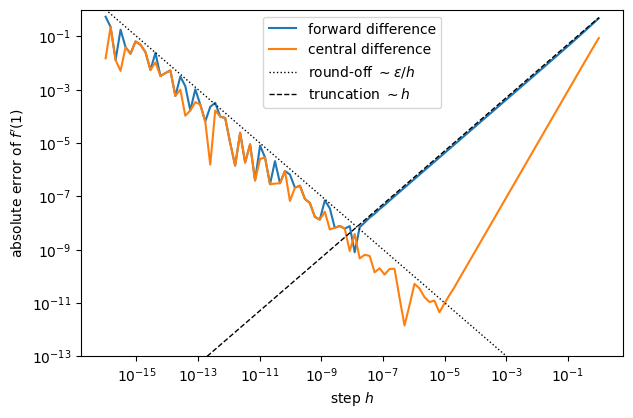

In [2]:
f, df_exact, x0 = np.sin, np.cos(1.0), 1.0
hs = np.logspace(-16, 0, 100)
err_fwd = np.abs((f(x0 + hs) - f(x0)) / hs - df_exact)
err_cen = np.abs((f(x0 + hs) - f(x0 - hs)) / (2 * hs) - df_exact)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(hs, err_fwd, label="forward difference")
ax.loglog(hs, err_cen, label="central difference")
ax.loglog(hs, 1e-16 / hs, "k:", lw=1, label=r"round-off $\sim\epsilon/h$")
ax.loglog(hs, 0.5 * hs, "k--", lw=1, label=r"truncation $\sim h$")
ax.set_xlabel("step $h$"); ax.set_ylabel("absolute error of $f'(1)$")
ax.set_ylim(1e-13, 1); ax.legend()
plt.show()

The plot is read from the right. For large $h$ the error decreases along the truncation line (as $h$ for the forward and as $h^2$ for the central difference).
Below the optimum it grows again along the round-off line, and the curves become jagged because rounding errors behave like random numbers.
The best achievable accuracy is about $10^{-9}$ (forward, at $h\approx10^{-8}$) or $10^{-11}$–$10^{-12}$ (central, at $h\approx10^{-6}$–$10^{-5}$), far from machine precision $\sim10^{-16}$.
The position of the optimum follows from adding the two errors. The Taylor expansion $f(x+h) = f + hf' + \tfrac12h^2f'' + \tfrac16h^3f''' + \dots$ gives the truncation error
$\tfrac12 h f''$ of the forward formula; in the central formula the $f''$ terms of $f(x+h)$ and $f(x-h)$ cancel, and the first remaining term is $\tfrac16 h^2 f'''$. For the forward difference the total error is about $\epsilon/h + |f''|\,h/2$, smallest at $h\sim\sqrt{\epsilon}\approx10^{-8}$.
For the central difference it is about $\epsilon/h + |f'''|\,h^2/6$, smallest at $h\sim\epsilon^{1/3}\approx10^{-5}$. Both estimates agree with the positions of the minima in the plot to within an order of magnitude.

### 1.2 Symbolic differentiation
Computer algebra (Mathematica, `sympy`) applies the rules of calculus to *expressions*. The result is exact and interpretable,
but expressions can grow enormously ("expression swell") and the approach does not work for functions defined by *programs*
(loops, `if` statements, matrix diagonalisation...).

In [3]:
import sympy as sp
x = sp.symbols("x")
expr = x
for _ in range(4):                     # a 'deep network' of 4 nested layers sin(x*sin(...))
    expr = sp.sin(x * expr)
d = sp.diff(expr, x)                   # symbolic derivative
print("function  :", expr)
# sp.count_ops counts the elementary operations (+, *, sin, cos, ...) in an expression
print("derivative has", sp.count_ops(d), "operations (function has", sp.count_ops(expr), ")")
print("first part of derivative:", str(d)[:200], "...")

function  : sin(x*sin(x*sin(x*sin(x**2))))
derivative has 43 operations (function has 8 )
first part of derivative: (x*(x*(2*x**2*cos(x**2) + sin(x**2))*cos(x*sin(x**2)) + sin(x*sin(x**2)))*cos(x*sin(x*sin(x**2))) + sin(x*sin(x*sin(x**2))))*cos(x*sin(x*sin(x*sin(x**2)))) ...


The function with 4 nested layers has 8 operations, its derivative 43. With 6 layers the numbers are 12 and 89: the derivative grows much faster
than the function. This growth is the expression swell.

### 1.3 Automatic differentiation
AD sits in between: every program — however complicated — is a composition of **elementary operations**
($+,\times,\sin,\exp,\log,\dots$) whose derivatives are known. AD records these operations and combines their local derivatives with the
**chain rule**, giving derivatives that are **exact to machine precision** at a cost of a small multiple of evaluating $f$ itself.

<hr/>
## 2. The computational graph

Consider the following function (adapted from the example in Baydin *et al.*, *Automatic differentiation in machine learning: a survey*, JMLR 2018):
$$y = f(x_1, x_2) = \ln x_1 + \cos x_2 - x_1 x_2 .$$
A **computational graph** is a diagram of a calculation: each node is one intermediate value, and an arrow from $v_a$ to $v_b$ means that $v_a$ is used
to compute $v_b$. We break the function into elementary steps. Following Baydin *et al.*, the inputs get the indices $-1$ and $0$, $v_{-1}=x_1$, $v_0 = x_2$,
so that the intermediate variables are numbered $v_1,\dots,v_5$:

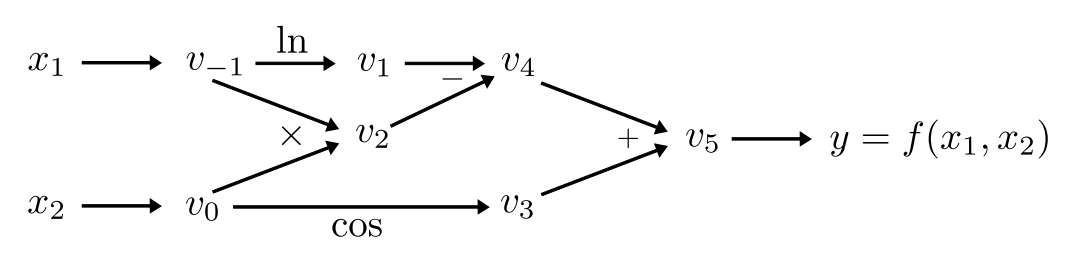

**Forward evaluation** at $(x_1,x_2) = (2, 1)$ — read the graph from left to right:

| step | value |
|---|---|
| $v_{-1} = x_1$ | $2$ |
| $v_0 = x_2$ | $1$ |
| $v_1 = \ln v_{-1}$ | $\ln 2 = 0.693$ |
| $v_2 = v_{-1} \times v_0$ | $2$ |
| $v_3 = \cos v_0$ | $\cos 1 = 0.540$ |
| $v_4 = v_1 - v_2$ | $-1.307$ |
| $v_5 = v_3 + v_4$ | $-0.767$ |
| $y = v_5$ | $-0.767$ |

Analytically: $\partial f/\partial x_1 = 1/x_1 - x_2 = -0.5$ and $\partial f/\partial x_2 = -\sin x_2 - x_1 = -2.841$. Below we obtain these numbers automatically.

<hr/>
## 3. Forward-mode AD and dual numbers

**Idea:** carry along with every intermediate value $v_i$ its derivative with respect to *one chosen input*, $\dot v_i = \partial v_i/\partial x_1$.
Each elementary step updates both by the chain rule. In the table, the *primal* is the ordinary value and the *tangent* is the derivative carried along with it
("w.r.t." = with respect to). The *seed* is the derivative we give to the inputs at the start: $\partial x_1/\partial x_1 = 1$ for the input we differentiate with respect to,
and $\partial x_2/\partial x_1 = 0$ for the other one.

| primal (value) | tangent (derivative w.r.t. $x_1$) | at $(2,1)$ |
|---|---|---|
| $v_{-1} = x_1 = 2$ | $\dot v_{-1} = 1$ (seed) | $1$ |
| $v_0 = x_2 = 1$ | $\dot v_0 = 0$ | $0$ |
| $v_1 = \ln v_{-1}$ | $\dot v_1 = \dot v_{-1}/v_{-1}$ | $0.5$ |
| $v_2 = v_{-1}v_0$ | $\dot v_2 = \dot v_{-1}v_0 + v_{-1}\dot v_0$ | $1$ |
| $v_3 = \cos v_0$ | $\dot v_3 = -\dot v_0\sin v_0$ | $0$ |
| $v_4 = v_1 - v_2$ | $\dot v_4 = \dot v_1 - \dot v_2$ | $-0.5$ |
| $v_5 = v_3 + v_4$ | $\dot v_5 = \dot v_3 + \dot v_4$ | $\mathbf{-0.5}$  (check) |

**Dual numbers** make this automatic. Extend real numbers by an element $\varepsilon$ with $\varepsilon^2=0$ (like the imaginary unit, but nilpotent):
$z = a + b\,\varepsilon$. Then
$$(a_1 + b_1\varepsilon) + (a_2 + b_2\varepsilon) = (a_1+a_2) + (b_1+b_2)\varepsilon,\qquad (a_1 + b_1\varepsilon)(a_2 + b_2\varepsilon) = a_1a_2 + (a_1b_2 + b_1a_2)\varepsilon,$$
and from the Taylor series $g(a + b\varepsilon) = g(a) + g'(a)\,b\varepsilon + \tfrac12 g''(a)\,b^2\varepsilon^2 + \dots$, in which every term containing $\varepsilon^2$ vanishes:
$$g(a + b\varepsilon) = g(a) + g'(a)\,b\,\varepsilon .$$
So evaluating $f$ on $x_1 + 1\cdot\varepsilon$ returns $f(x) + \frac{\partial f}{\partial x_1}\varepsilon$: the coefficient of $\varepsilon$ in the result is the derivative.
In code: a small class with **operator overloading**: defining `__add__` and `__mul__` makes `+` and `*` work on `Dual` objects.
Three Python details appear in the class for the first time:
- `isinstance(z, Dual)` checks whether `z` is already a dual number. If it is a plain number such as `3`, the method `lift` turns it into `Dual(3, 0)`
  (a constant has derivative zero), so that expressions like `x1 * 3` work.
- `@staticmethod` marks a function that belongs to the class but does not receive `self`; it is called as `Dual.lift(z)`.
- `__radd__` and `__rmul__` are used by Python when the plain number stands on the *left*, as in `3 + Dual(...)`.

In [4]:
class Dual:
    """Dual number a + b*eps with eps^2 = 0.  'a' = value, 'b' = derivative."""

    def __init__(self, a, b=0.0):
        self.a, self.b = a, b

    @staticmethod
    def lift(z):                      # turn plain numbers into duals with zero derivative
        return z if isinstance(z, Dual) else Dual(z, 0.0)

    def __add__(self, other):
        other = Dual.lift(other)
        return Dual(self.a + other.a, self.b + other.b)

    def __sub__(self, other):
        other = Dual.lift(other)
        return Dual(self.a - other.a, self.b - other.b)

    def __mul__(self, other):         # product rule
        other = Dual.lift(other)
        return Dual(self.a * other.a, self.a * other.b + self.b * other.a)

    __radd__ = __add__                # so that 3 + Dual(...) also works
    __rmul__ = __mul__

    def __repr__(self):
        return f"Dual(value={self.a:.6f}, derivative={self.b:.6f})"

# elementary functions: g(a + b eps) = g(a) + g'(a) b eps
def d_log(z): return Dual(math.log(z.a), z.b / z.a)
def d_cos(z): return Dual(math.cos(z.a), -math.sin(z.a) * z.b)
def d_sin(z): return Dual(math.sin(z.a), math.cos(z.a) * z.b)

The function of Section 2 written with dual-number operations. The derivative with respect to $x_1$ is obtained by giving $x_1$ the derivative part 1 and $x_2$ the derivative part 0:

In [5]:
def f_dual(x1, x2):
    return d_log(x1) + d_cos(x2) - x1 * x2

# derivative w.r.t. x1: seed x1 with derivative 1, x2 with 0
print("d/dx1:", f_dual(Dual(2.0, 1.0), Dual(1.0, 0.0)))
# derivative w.r.t. x2: a SECOND forward pass with a different seed
print("d/dx2:", f_dual(Dual(2.0, 0.0), Dual(1.0, 1.0)))
print("exact:", 1/2 - 1, -math.sin(1) - 2)

d/dx1: Dual(value=-0.766551, derivative=-0.500000)
d/dx2: Dual(value=-0.766551, derivative=-2.841471)
exact: -0.5 -2.8414709848078967


Both passes return the value $-0.7666$ of the table in Section 2 together with one derivative each, and both derivatives equal the exact results.

**Cost of forward mode:** one pass per input variable. Efficient for $f:\mathbb R\to\mathbb R^m$ (few inputs, many outputs),
inefficient for a loss $\mathcal L:\mathbb R^{10^9}\to\mathbb R$, which would need $10^9$ passes.
<hr/>
## 4. Reverse-mode AD = backpropagation

**Idea:** first run the program forward and *record* the graph. Then go **backwards** from the output, computing the **adjoints**
$$\bar v_i = \frac{\partial y}{\partial v_i}.$$
Start with $\bar v_5 = \partial y/\partial y = 1$. The chain rule says: the adjoint of a node is the sum, over all nodes $v_j$ that *use* it, of $\bar v_j\,\partial v_j/\partial v_i$.

| backward step | at $(2,1)$ |
|---|---|
| $\bar v_5 = 1$ | $1$ |
| $\bar v_4 = \bar v_5\,\partial v_5/\partial v_4 = \bar v_5$ | $1$ |
| $\bar v_3 = \bar v_5\,\partial v_5/\partial v_3 = \bar v_5$ | $1$ |
| $\bar v_2 = \bar v_4\,\partial v_4/\partial v_2 = -\bar v_4$ | $-1$ |
| $\bar v_1 = \bar v_4\,\partial v_4/\partial v_1 = \bar v_4$ | $1$ |
| $\bar v_0 = \bar v_3\,(-\sin v_0) + \bar v_2\, v_{-1}$ | $-0.841 - 2 = \mathbf{-2.841}$  (check) |
| $\bar v_{-1} = \bar v_1 / v_{-1} + \bar v_2\, v_0$ | $0.5 - 1 = \mathbf{-0.5}$  (check) |

**One** backward pass gives the derivatives with respect to **all** inputs. Cost: a small constant times one evaluation of $f$, independent of the number of parameters.
This is why reverse mode (= *backpropagation* in the neural-network language) is the method used to train neural networks.

Below is a minimal implementation of what PyTorch does internally (in the spirit of A. Karpathy's *micrograd*).
Each `Var` stores its value, the `Var`s it was computed from (`parents`) and the local derivatives with respect to them.
The method `backward` must visit the nodes in an order in which every node comes after all nodes it depends on (a *topological order*).
The inner function `build` produces it: it first calls itself on all parents and only then appends the node (a depth-first traversal).
`id(v)` is a number that identifies the Python object `v`; the set `visited` records the nodes already placed, so that a node used twice,
such as $x_1$, appears in the list only once. Going through this list in reverse order then visits the output first and the inputs last.

In [6]:
class Var:
    """A scalar that remembers how it was computed, so that gradients can flow back."""

    def __init__(self, value, parents=(), local_grads=(), name=""):
        self.value = value
        self.grad = 0.0                  # will hold dy/d(this) after backward()
        self.parents = parents           # the Vars this one was computed from
        self.local_grads = local_grads   # d(this)/d(parent) for each parent
        self.name = name

    def __add__(self, other): return Var(self.value + other.value, (self, other), (1.0, 1.0))
    def __sub__(self, other): return Var(self.value - other.value, (self, other), (1.0, -1.0))
    def __mul__(self, other): return Var(self.value * other.value, (self, other), (other.value, self.value))

    def backward(self):
        # 1) order the graph so that every node comes after all nodes it depends on (topological sort)
        order, visited = [], set()
        def build(v):
            if id(v) not in visited:
                visited.add(id(v))
                for p in v.parents:
                    build(p)
                order.append(v)
        build(self)
        # 2) seed and propagate adjoints from the output back to the inputs
        self.grad = 1.0
        for v in reversed(order):
            for parent, local in zip(v.parents, v.local_grads):
                parent.grad += v.grad * local     # chain rule; '+=' sums over all paths

def v_log(v): return Var(math.log(v.value), (v,), (1.0 / v.value,))
def v_cos(v): return Var(math.cos(v.value), (v,), (-math.sin(v.value),))

The same function with `Var` objects: the forward pass builds the graph, and one backward pass gives both derivatives:

In [7]:
x1, x2 = Var(2.0, name="x1"), Var(1.0, name="x2")
y = v_log(x1) + v_cos(x2) - x1 * x2       # forward pass builds the graph
y.backward()                              # ONE backward pass
print(f"y = {y.value:.4f}")
print(f"dy/dx1 = {x1.grad:.4f},  dy/dx2 = {x2.grad:.4f}")

y = -0.7666
dy/dx1 = -0.5000,  dy/dx2 = -2.8415


<hr/>
## 5. `torch.autograd`

PyTorch implements exactly this reverse-mode machinery for tensors and hundreds of operations (including `matmul`, `eigh`, `fft`, ...).
- `requires_grad=True` marks a tensor as a variable we want derivatives with respect to;
- every operation on it records a node of the graph (`grad_fn`);
- `y.backward()` runs the backward pass; the gradients land in `.grad` of the **leaf tensors**. A leaf is a tensor created directly by us (below: `x1` and `x2`),
  not as the result of an operation; the leaves are the inputs of the graph.

In [8]:
x1 = torch.tensor(2.0, requires_grad=True)
x2 = torch.tensor(1.0, requires_grad=True)

y = torch.log(x1) + torch.cos(x2) - x1 * x2
print("y       :", y)                     # grad_fn=<SubBackward0>: the last operation recorded in the graph
y.backward()
print("dy/dx1  :", x1.grad.item())      # .item() converts a one-element tensor to a Python number
print("dy/dx2  :", x2.grad.item())

y       : tensor(-0.7666, grad_fn=<SubBackward0>)
dy/dx1  : -0.5
dy/dx2  : -2.8414709848078967


The recorded graph can be traversed backwards from `y.grad_fn`. It contains the same elementary operations as the graph in Section 2; the grouping differs
because Python evaluates `log(x1) + cos(x2)` first and subtracts `x1*x2` last.

In [9]:
def show_graph(fn, depth=0):
    # Print the name of each graph node, indented by its distance from the output.
    # fn.next_functions lists the nodes that fn received its inputs from (pairs (node, index));
    # type(fn).__name__ is the class name of the node, e.g. 'MulBackward0' for a multiplication.
    if fn is None:                                   # inputs that need no gradient appear as None
        return
    print("  " * depth + type(fn).__name__)
    for parent, _ in fn.next_functions:
        show_graph(parent, depth + 1)

y = torch.log(x1) + torch.cos(x2) - x1 * x2
show_graph(y.grad_fn)     # 'AccumulateGrad' = a leaf: the place where .grad is stored

SubBackward0
  AddBackward0
    LogBackward0
      AccumulateGrad
    CosBackward0
      AccumulateGrad
  MulBackward0
    AccumulateGrad
    AccumulateGrad


### 5.1 Derivatives of a whole curve at once
`backward()` starts from a single number (a scalar), so for a tensor $x$ of many points we sum the outputs first. Since each term of the sum depends only on its own point,
$\partial\big(\sum_j f(x_j)\big)/\partial x_i = f'(x_i)$: the gradient is the derivative at every point. Here: $\frac{d}{dx}\big[e^{-x^2/2}\sin 3x\big]$, compared with the analytic result.

max |autograd - analytic| = 4.440892098500626e-16


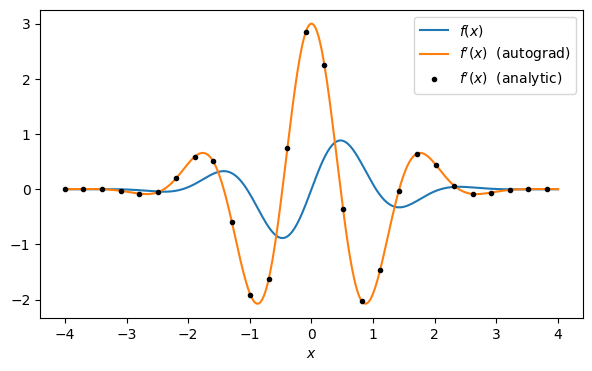

In [10]:
x = torch.linspace(-4, 4, 400, requires_grad=True)
y = torch.exp(-x**2 / 2) * torch.sin(3 * x)
y.sum().backward()

xd = x.detach()                                   # detach: a plain tensor without graph, for plotting
analytic = torch.exp(-xd**2 / 2) * (3 * torch.cos(3 * xd) - xd * torch.sin(3 * xd))
print("max |autograd - analytic| =", (x.grad - analytic).abs().max().item())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xd, y.detach(), label="$f(x)$")
ax.plot(xd, x.grad, label="$f'(x)$  (autograd)")
ax.plot(xd[::15], analytic[::15], "k.", label="$f'(x)$  (analytic)")
ax.set_xlabel("$x$"); ax.legend(); plt.show()

The largest difference, about $4\times10^{-16}$, is at the level of float64 rounding: the autograd derivative is exact up to machine precision.

### 5.2 Higher derivatives: `torch.autograd.grad` with `create_graph=True`
`torch.autograd.grad(y, x)` returns the gradient instead of storing it in `.grad`. With `create_graph=True`
the gradient computation itself is recorded, so it can be differentiated again.
Physics example: a potential $V(x)$ → force $F = -V'(x)$ and curvature $V''(x)$; the curvature at the minimum gives the vibration frequency $\omega = \sqrt{V''(r_0)/\mu}$ ($\mu$ = reduced mass).
Take the Morse potential $V(r) = D\,(1 - e^{-a(r - r_0)})^2$, a model of the bond between two atoms ($D$ is the depth of the well, $r_0$ the bond length, $a$ sets the width), for which $V''(r_0) = 2Da^2$ (the values of $D$, $a$, $r_0$ below are arbitrary).

`torch.autograd.grad` returns a *tuple* with one gradient per input tensor, even when there is only one input. The notation `(dV,) = ...` unpacks
this one-element tuple; it is equivalent to `dV = torch.autograd.grad(...)[0]`.

In [11]:
D, a, r0 = 4.0, 1.5, 1.0
r = torch.tensor(r0, requires_grad=True)
V = D * (1 - torch.exp(-a * (r - r0)))**2

(dV,) = torch.autograd.grad(V, r, create_graph=True)   # first derivative, still differentiable
(d2V,) = torch.autograd.grad(dV, r)                    # second derivative
print(f"V'(r0)  = {dV.item():.3e}   (equilibrium -> 0)")
print(f"V''(r0) = {d2V.item():.6f}   exact 2 D a^2 = {2*D*a**2}")

V'(r0)  = 0.000e+00   (equilibrium -> 0)
V''(r0) = 18.000000   exact 2 D a^2 = 18.0


### 5.3 Four common pitfalls

In [12]:
# Pitfall 1: gradients ACCUMULATE. Calling backward twice adds up the gradients.
w = torch.tensor(3.0, requires_grad=True)
for i in range(3):
    loss = w**2
    loss.backward()
    print(f"iteration {i}: w.grad = {w.grad.item()}   (true gradient: 6)")
# -> every training loop must reset them: w.grad = None  or  optimizer.zero_grad()  (Section 7)

iteration 0: w.grad = 6.0   (true gradient: 6)
iteration 1: w.grad = 12.0   (true gradient: 6)
iteration 2: w.grad = 18.0   (true gradient: 6)


**Pitfall 2:** the graph is freed after `backward()` to save memory. A second gradient needs a new forward pass, which every training step makes anyway:

In [13]:
# Pitfall 2: the graph is freed after backward(); calling backward on it again raises an error
w = torch.tensor(3.0, requires_grad=True)
loss = w**2
loss.backward()
try:
    loss.backward()
except RuntimeError as e:
    print("RuntimeError:", str(e)[:90], "...")

RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after ...


**Pitfall 3:** converting a tensor that requires gradients to NumPy:

In [14]:
# Pitfall 3: .numpy() cannot be called on a tensor that requires grad -> use .detach() first
w = torch.tensor([1.0, 2.0], requires_grad=True)
try:
    (w**2).numpy()
except RuntimeError as e:
    print("RuntimeError:", str(e)[:80], "...")
print("fixed:", (w**2).detach().numpy())

RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() ins ...
fixed: [1. 4.]


**Pitfall 4:** updating parameters by hand. The update itself is an operation on `w`; if it were recorded, the graph would keep growing from one step to the next.
Inside `with torch.no_grad():` nothing is recorded. The update must also be *in place* (`w -= ...`): it changes the numbers stored in the existing tensor `w`,
which stays the same leaf tensor with `requires_grad=True`. Writing `w = w - 0.1 * w.grad` would instead create a new tensor and bind the name `w` to it. Inside `no_grad` the new tensor does not
require gradients at all; outside `no_grad` it is not a leaf and its `.grad` stays `None` after the next backward pass. In both cases the training stops working.

In [15]:
# Pitfall 4: parameter updates must NOT be recorded in the graph -> wrap them in torch.no_grad()
w = torch.tensor(3.0, requires_grad=True)
loss = w**2
loss.backward()
with torch.no_grad():
    w -= 0.1 * w.grad          # an in-place update of a leaf, outside the graph
w.grad = None                  # reset for the next step (pitfall 1)
print("updated w:", w)

updated w: tensor(2.4000, requires_grad=True)


<hr/>
## 6. Physics: differentiating through a diagonalisation

Consider the double-well potential (harmonic trap + Gaussian barrier of height $\kappa$):
$$\hat H(\kappa) = -\frac{1}{2}\frac{d^2}{dx^2} + \frac{1}{2}x^2 + \kappa\, e^{-x^2/2}.$$
**Question:** how do the energies $E_n(\kappa)$ respond to changes of the barrier, $dE_n/d\kappa$?

The program is: *build the matrix $\bar H(\kappa)$ (the bar denotes the matrix of $\hat H$ on the grid) → diagonalise → pick eigenvalue $n$*. There is no closed formula, but every step
(including `torch.linalg.eigh`) is differentiable, so autograd gives $dE_n/d\kappa$ **exactly** (up to the grid discretisation).

Why two wells appear: $V'(x) = x\,(1 - \kappa e^{-x^2/2})$ and $V''(0) = 1-\kappa$. For $\kappa > 1$ the point $x = 0$ becomes a maximum, and two minima appear at
$x = \pm\sqrt{2\ln\kappa}$ (for example $\pm1.67$ at $\kappa = 4$).

The box $[-6, 6]$ is much wider than the low-lying states. With $N_x = 300$ points the spacing is $\Delta x \approx 0.04$,
small compared with the scale (of order 1) on which these states vary. The lowest four energies at $\kappa = 4$ change by less than $10^{-3}$ (relative change below $2\cdot10^{-4}$)
when $N_x$ is increased from 300 to 1000, so any $N_x$ of a few hundred gives the same picture; larger $N_x$ only makes the diagonalisation slower.

Functions used for the first time:
- `torch.diag(v, k)` applied to a *vector* `v` builds a matrix with `v` on the $k$-th diagonal ($k = 1$: the diagonal above the main one, $k = -1$: the diagonal below it, $k = 0$ or omitted: the main diagonal).
- `torch.linalg.eigvalsh(H)` returns only the eigenvalues of a symmetric matrix; `torch.linalg.eigh(H)` returns the eigenvalues *and* the eigenvectors.
  Both return the eigenvalues in ascending order, so `[:n_levels]` selects the lowest levels. We use `eigvalsh` whenever the eigenvectors are not needed: it does less work.

In [16]:
# Grid: psi''(x_i) ~ (psi_{i+1} - 2 psi_i + psi_{i-1}) / dx^2, and psi = 0 beyond the ends of the grid
# (hard walls at x = -6 and x = 6, far from where the wavefunctions live).
L_box, Nx = 12.0, 300
x = torch.linspace(-L_box / 2, L_box / 2, Nx)
dx = x[1] - x[0]

# kinetic part (does not depend on kappa): built once
ones = torch.ones(Nx - 1)
H_kin = -0.5 / dx**2 * (torch.diag(ones, 1) - 2 * torch.eye(Nx) + torch.diag(ones, -1))

def potential(x, kappa):
    return 0.5 * x**2 + kappa * torch.exp(-x**2 / 2)

def hamiltonian(kappa):
    """Matrix of H(kappa) on the grid; differentiable w.r.t. kappa."""
    return H_kin + torch.diag(potential(x, kappa))

def energies(kappa, n_levels=4):
    return torch.linalg.eigvalsh(hamiltonian(kappa))[:n_levels]

The potential and the densities of the four lowest states (shifted by their energies) for four barrier heights.
`eigh` returns the eigenvectors as the **columns** of the matrix `psi`: `psi[:, n]` (all rows, column $n$) is the $n$-th eigenstate, belonging to `E[n]`.
Taking a row, `psi[n]`, would be a mistake. The eigenvectors are normalised as vectors, $\sum_i|\psi_n(x_i)|^2 = 1$; dividing by $\Delta x$ turns this into a
probability density with $\sum_i |\psi_n(x_i)|^2/\Delta x\cdot\Delta x = 1$, the discrete form of $\int|\psi|^2dx = 1$. The extra factor 1.5 only enlarges the curves for visibility.

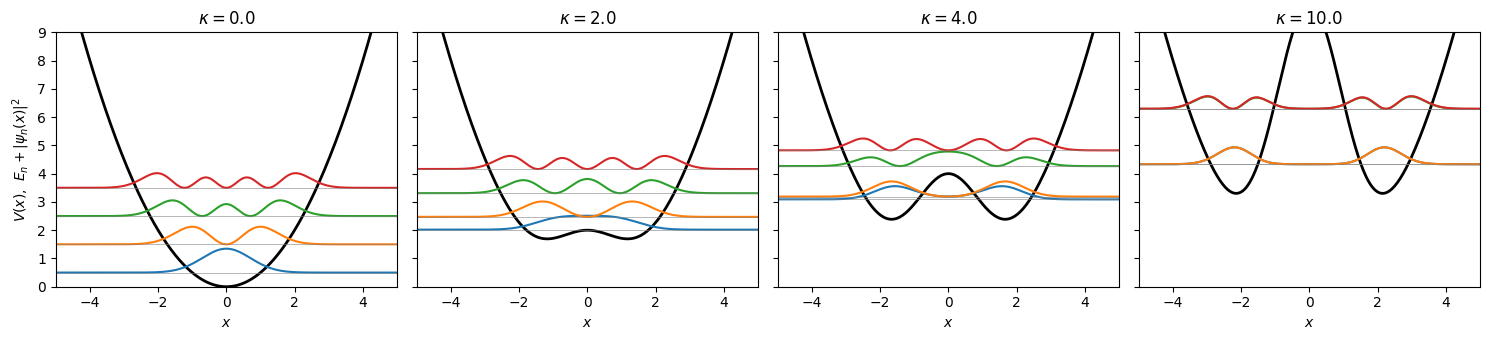

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, kappa in zip(axes, [0.0, 2.0, 4.0, 10.0]):
    E, psi = torch.linalg.eigh(hamiltonian(torch.tensor(kappa)))
    ax.plot(x, potential(x, torch.tensor(kappa)), "k", lw=2)
    for n in range(4):
        ax.plot(x, E[n] + 1.5 * psi[:, n]**2 / dx, lw=1.5)       # |psi_n|^2 (scaled by 1.5) shifted by E_n
        ax.axhline(E[n], color="gray", lw=0.4)
    ax.set_title(rf"$\kappa = {kappa}$"); ax.set_xlabel("$x$"); ax.set_xlim(-5, 5); ax.set_ylim(0, 9)
axes[0].set_ylabel(r"$V(x)$, $\;E_n + |\psi_n(x)|^2$")
fig.tight_layout(); plt.show()

In the figure, for $\kappa = 0$ the levels are those of the harmonic oscillator, $E_n = n + \tfrac12$. As $\kappa$ grows, the barrier pushes the states out of the centre
and the levels move up. At $\kappa = 10$ they form pairs of almost equal energy, $E_1 - E_0 \approx 5\times10^{-4}$ and $E_3 - E_2 \approx 9\times10^{-3}$,
and the two curves of each pair lie on top of each other.

**One derivative with autograd.** The value $\kappa = 4$ is an arbitrary choice in the double-well regime $\kappa > 1$; the checks below agree equally well for other values.

In [18]:
kappa = torch.tensor(4.0, requires_grad=True)
E0 = energies(kappa)[0]
E0.backward()
print(f"E_0(kappa=4) = {E0.item():.6f},   dE_0/dkappa = {kappa.grad.item():.6f}")

E_0(kappa=4) = 3.089526,   dE_0/dkappa = 0.388432


**Check 1 — Hellmann–Feynman theorem.** For a normalised eigenstate, $\dfrac{dE_n}{d\kappa} = \Big\langle\psi_n\Big|\dfrac{\partial\hat H}{\partial\kappa}\Big|\psi_n\Big\rangle = \langle\psi_n|\,e^{-x^2/2}\,|\psi_n\rangle$.
Here $\langle\psi_n|\hat A|\psi_n\rangle$ is the expectation value of $\hat A$ in the state $\psi_n$. On the grid (eigenvectors from `eigh` are normalised as vectors) it is
$\sum_i |\psi_n(x_i)|^2 e^{-x_i^2/2}$, because $d\bar H/d\kappa = \mathrm{diag}(e^{-x_i^2/2})$.
On the grid the theorem follows in one line. With $E_n = \vec\psi_n^T\bar H\vec\psi_n$ and $\vec\psi_n^T\vec\psi_n = 1$, the product rule gives
$dE_n/d\kappa = \vec\psi_n^T(d\bar H/d\kappa)\vec\psi_n + 2\,\vec\psi_n^T\bar H\,(d\vec\psi_n/d\kappa)$. Since $\bar H$ is symmetric, $\vec\psi_n^T\bar H = E_n\vec\psi_n^T$,
and the last term is $2E_n\vec\psi_n^T d\vec\psi_n/d\kappa = E_n\,d(\vec\psi_n^T\vec\psi_n)/d\kappa = 0$. The change of the eigenvector does not contribute.

**Check 2 — central finite differences.** Section 1 found the optimal step near $10^{-6}$–$10^{-5}$ for $\sin x$. Here any $h$ between about $10^{-3}$ and $10^{-5}$ gives
agreement with autograd to better than $10^{-8}$; we take the middle value $h = 10^{-4}$.

In [19]:
k0 = 4.0
_, psi = torch.linalg.eigh(hamiltonian(torch.tensor(k0)))
hf = torch.sum(psi[:, 0]**2 * torch.exp(-x**2 / 2)).item()
h = 1e-4
fd = ((energies(torch.tensor(k0 + h))[0] - energies(torch.tensor(k0 - h))[0]) / (2 * h)).item()
print(f"autograd          : {kappa.grad.item():.10f}")
print(f"Hellmann-Feynman  : {hf:.10f}")
print(f"finite difference : {fd:.10f}")

autograd          : 0.3884316631
Hellmann-Feynman  : 0.3884316631
finite difference : 0.3884316634


**The full picture:** $E_n(\kappa)$ and $dE_n/d\kappa$ for the four lowest levels, $\kappa\in[0,12]$.
For each of 121 values of $\kappa$ (step 0.1) we compute all four derivatives with `torch.autograd.functional.jacobian`.
For a function $\vec f$ of $\vec x$, `jacobian(f, x)` evaluates $\vec f$ at `x` and returns the matrix of derivatives $\partial f_i/\partial x_j$ (one backward pass per output $f_i$).
Here $f$ maps one number $\kappa$ to four energies, so the result is a vector of four derivatives. `jacobian` switches on gradient tracking for its input argument itself,
so `k` needs no `requires_grad=True`. The energies themselves are stored with `.detach()`, which keeps only the numbers and not the computational graph
(otherwise 121 graphs would be kept in memory). At the end, `torch.stack` turns the list of 121 tensors of shape `(4,)` into one tensor of shape `(121, 4)`.

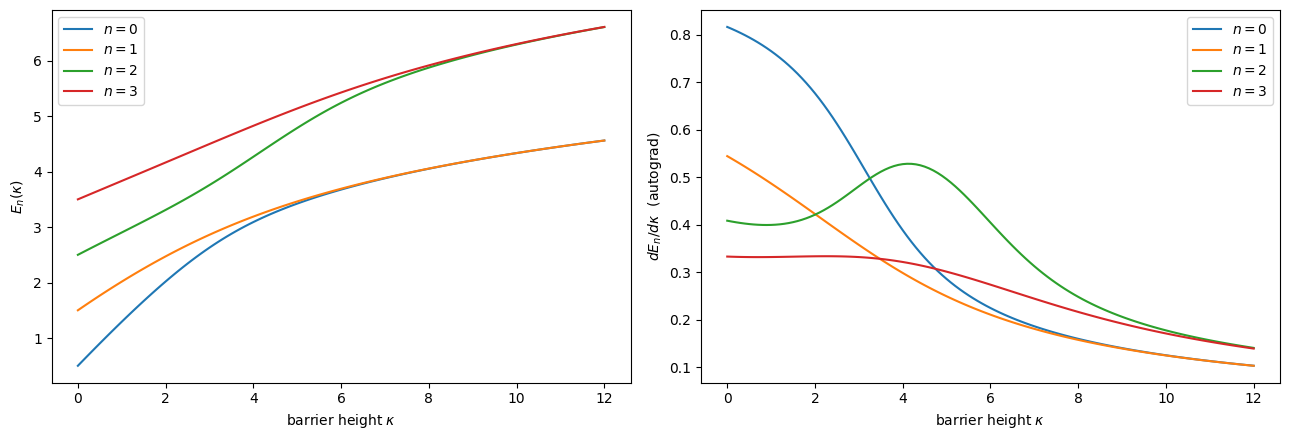

In [20]:
kappas = torch.linspace(0, 12, 121)
E_all, dE_all = [], []
for k in kappas:
    E_all.append(energies(k).detach())
    dE_all.append(torch.autograd.functional.jacobian(energies, k))   # shape (4,): dE_n/dkappa
E_all, dE_all = torch.stack(E_all), torch.stack(dE_all)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for n in range(4):
    axes[0].plot(kappas, E_all[:, n], label=f"$n={n}$")
    axes[1].plot(kappas, dE_all[:, n], label=f"$n={n}$")
axes[0].set_ylabel(r"$E_n(\kappa)$"); axes[1].set_ylabel(r"$dE_n/d\kappa$  (autograd)")
for ax in axes:
    ax.set_xlabel(r"barrier height $\kappa$"); ax.legend()
fig.tight_layout(); plt.show()

**Interpretation.** $dE_n/d\kappa = \langle e^{-x^2/2}\rangle_n$ is the probability-weighted overlap of the state with the barrier.
For large $\kappa$ all four states are pushed out of the centre and $dE_n/d\kappa$ decreases (for $n=2$ only above $\kappa\approx4$; below that it first increases); pairs of levels $(0,1)$, $(2,3)$
merge into quasi-degenerate **tunnelling doublets** (pairs of nearly equal energy; the two states of a pair are spread symmetrically and antisymmetrically over the two wells,
and their small splitting is caused by tunnelling through the barrier) — and their derivatives become equal, because both states of a doublet see the barrier the same way.

> **A subtle point.** Derivatives of *eigenvalues* are well defined. Derivatives of *eigenvectors* contain factors $1/(E_n - E_m)$ and blow up
> at (near-)degeneracies. PyTorch's backward formula for `eigh` builds the full matrix of factors $1/(E_j - E_i)$, so exact degeneracies anywhere in the spectrum
> give `inf`, and `inf` multiplied by zero gives `nan`, even for pairs that do not contribute mathematically. The PyTorch documentation of `eigh` warns about this.

To summarise this section: **any computation built from differentiable operations can be differentiated.** The same mechanism that trains neural networks
is used to optimise Hamiltonians, quantum circuits (the variational quantum eigensolver VQE and the quantum approximate optimisation algorithm QAOA, later in the course) and control pulses.
<hr/>
## 7. From gradients to optimisation

### 7.1 Gradient descent written by hand
Minimise the Rosenbrock function $f(x, y) = (1-x)^2 + 100\,(y - x^2)^2$ (minimum at $(1,1)$ at the bottom of a long, curved, flat valley — a simple model of a hard loss landscape).

The starting point $(-1.5, 2)$ lies on the far side of the curved valley, so the path has to follow its whole length; other starts at a distance of order 1–3 from $(1,1)$
show the same behaviour. The 3000 steps are chosen to show the slow motion along the valley, not to reach convergence.
The positions are stored with `p.detach().clone()`: `detach()` alone would return a tensor that *shares memory* with `p`, and since `p` is changed in place
in every step, all stored entries would change with it and end up equal to the final position. `clone()` makes an independent copy.

In [21]:
def rosenbrock(p):
    return (1 - p[0])**2 + 100 * (p[1] - p[0]**2)**2

def gradient_descent(lr, n_steps=3000, start=(-1.5, 2.0)):
    p = torch.tensor(start, requires_grad=True)
    path = [p.detach().clone()]
    for _ in range(n_steps):
        loss = rosenbrock(p)
        loss.backward()                  # 1) gradient by autograd
        with torch.no_grad():
            p -= lr * p.grad             # 2) step downhill
        p.grad = None                    # 3) reset accumulated gradient
        path.append(p.detach().clone())
    return torch.stack(path)

path = gradient_descent(lr=1e-3)
print("final point:", path[-1], " f =", rosenbrock(path[-1]).item())

final point: tensor([0.7796, 0.6068])  f = 0.048669156394873424


The path of gradient descent drawn on the Rosenbrock landscape (the red star is the minimum).
`torch.meshgrid(xg, yg, indexing="xy")` builds two 2D arrays `XG`, `YG` holding the $x$ and $y$ coordinates of every point of the plotting grid,
in the layout of shape `(len(yg), len(xg))` that `contourf` expects. The values of $f$ on the plot range from 0 to about $2.5\times10^3$, so the colour scale
shows $\log_{10}(f + 10^{-3})$; the small constant avoids $\log 0$ at the minimum, and any value well below the plotted levels of $f$ works.

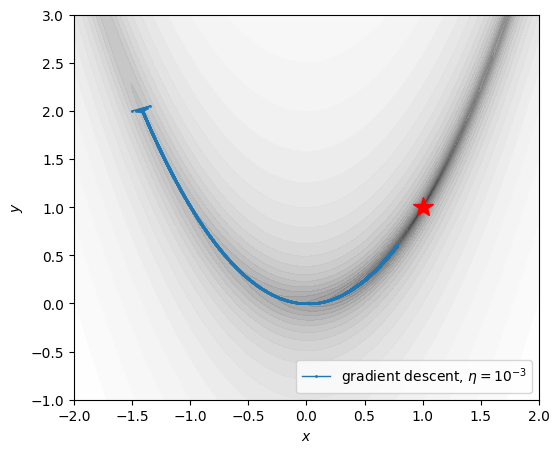

In [22]:
xg, yg = torch.linspace(-2, 2, 300), torch.linspace(-1, 3, 300)
XG, YG = torch.meshgrid(xg, yg, indexing="xy")
FG = rosenbrock(torch.stack([XG, YG]))

def landscape(ax):
    ax.contourf(XG, YG, torch.log10(FG + 1e-3), levels=40, cmap="Greys_r", alpha=0.8)
    ax.plot(1, 1, "r*", ms=15)
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$")

fig, ax = plt.subplots(figsize=(6, 5))
landscape(ax)
ax.plot(path[:, 0], path[:, 1], ".-", color="C0", ms=2, lw=1, label="gradient descent, $\\eta=10^{-3}$")
ax.legend(loc="lower right"); plt.show()

Gradient descent (GD) quickly falls into the valley, then crawls slowly along it. A larger learning rate helps along the valley — but makes the steps
across the steep walls unstable. The limit can be computed. Near a minimum, $f$ is approximately quadratic with the Hessian matrix $\partial^2 f/\partial x_i\partial x_j$ as curvature.
There the gradient is approximately $\nabla f \approx \nabla^2 f\,(\vec x - \vec x^\ast)$, where $\nabla^2 f$ is the Hessian and $\vec x^\ast$ the minimum, so one GD step maps
$\vec x - \vec x^\ast \to (\mathbf 1 - \eta\,\nabla^2 f)(\vec x - \vec x^\ast)$. Along an eigenvector of the Hessian with eigenvalue $\lambda$, one step therefore multiplies the distance from the minimum by $(1 - \eta\lambda)$.
The iteration converges only if $|1-\eta\lambda| < 1$ for all eigenvalues, i.e. $\eta < 2/\lambda_{\max}$.
At the Rosenbrock minimum the eigenvalues are $0.40$ and $1001.6$, so $\eta$ must stay below $2/1001.6 \approx 2.0\times10^{-3}$.
The flat direction ($\lambda = 0.4$) then shrinks by only a factor $1 - 0.4\,\eta \approx 0.9992$ per step, which is why GD is slow.

The cell below compares $\eta = 10^{-3}$, $\eta = 1.9\times10^{-3}$ (slightly below the limit, much closer to the minimum after 3000 steps) and $\eta = 2.5\times10^{-3}$ (above the limit:
the iteration diverges, and the result is `nan`, "not a number").
The range of usable learning rates is narrow. Better optimisers address the mismatch between flat and steep directions.

In [23]:
for lr in [1e-3, 1.9e-3, 2.5e-3]:
    final = gradient_descent(lr=lr)[-1]
    print(f"eta = {lr:.1e}:  final point = {final.numpy().round(4)},  f = {rosenbrock(final).item():.2e}")

eta = 1.0e-03:  final point = [0.7796 0.6068],  f = 4.87e-02


eta = 1.9e-03:  final point = [0.9756 0.9517],  f = 5.97e-04


eta = 2.5e-03:  final point = [nan nan],  f = nan


### 7.2 `torch.optim`: the optimiser zoo
PyTorch's optimisers implement the update rule. For most optimisers the training loop has the same 4 lines (L-BFGS, used in Section 8, is an exception):
```python
optimizer.zero_grad()   # reset gradients
loss = f(params)        # forward pass
loss.backward()         # backward pass
optimizer.step()        # update parameters
```
We compare (see Lecture Notes, *The Zoo of Optimization Algorithms*):
- **SGD**: $\theta \leftarrow \theta - \eta g$, with $g$ the gradient. The name *stochastic* gradient descent refers to estimating $g$ from a random part of the
  training data. Here there are no data, $g$ is exact, and SGD is plain gradient descent.
- **SGD + momentum**: $v \leftarrow \gamma v - \eta g$, $\theta\leftarrow\theta + v$ — a "heavy ball" that builds up speed along the valley.
  $\gamma = 0.9$ is the conventional value: the velocity is then an average over roughly the last $1/(1-\gamma) = 10$ gradients.
- **RMSprop**: per-parameter step $\eta\,g/\sqrt{E[g^2]}$ — rescales steep and flat directions. Here $E[g^2]$ is a running average of the squared gradient,
  updated in every step as $E \leftarrow \rho E + (1-\rho)\,g^2$ (PyTorch default $\rho = 0.99$), separately for each parameter.
- **Adam**: momentum + RMSprop. Both running averages start at zero, which makes them too small in the first steps; the *bias correction* divides them by
  $1-\beta^t$ to compensate ($t$ = step number; $\beta$ = the decay factor of the average, by default $0.9$ for the gradient and $0.999$ for its square). Adam is the default choice in deep learning.

The learning rates differ between the optimisers because $\eta$ means different things. With momentum $\gamma = 0.9$, on a steady slope the steps add up to
$\eta/(1-\gamma) = 10\,\eta$, so $\eta$ is reduced. RMSprop and Adam divide the gradient by its typical size, so their $\eta$ is roughly the step length in parameter
space and can be much larger. Each value was set by hand to give a stable run; the comparison shows typical behaviour, not the best possible setting of each method.

Python details in the code: a class such as `torch.optim.Adam` can be passed to a function like any other object. In the definition `def run(opt_class, ..., **opt_kwargs)`,
`**opt_kwargs` collects all remaining keyword arguments into a dictionary, and in the call `opt_class([p], **opt_kwargs)` the `**` unpacks the dictionary back into
keyword arguments. The line `results = {...}` is a *dictionary comprehension*: it runs every set-up and stores the result under its name.

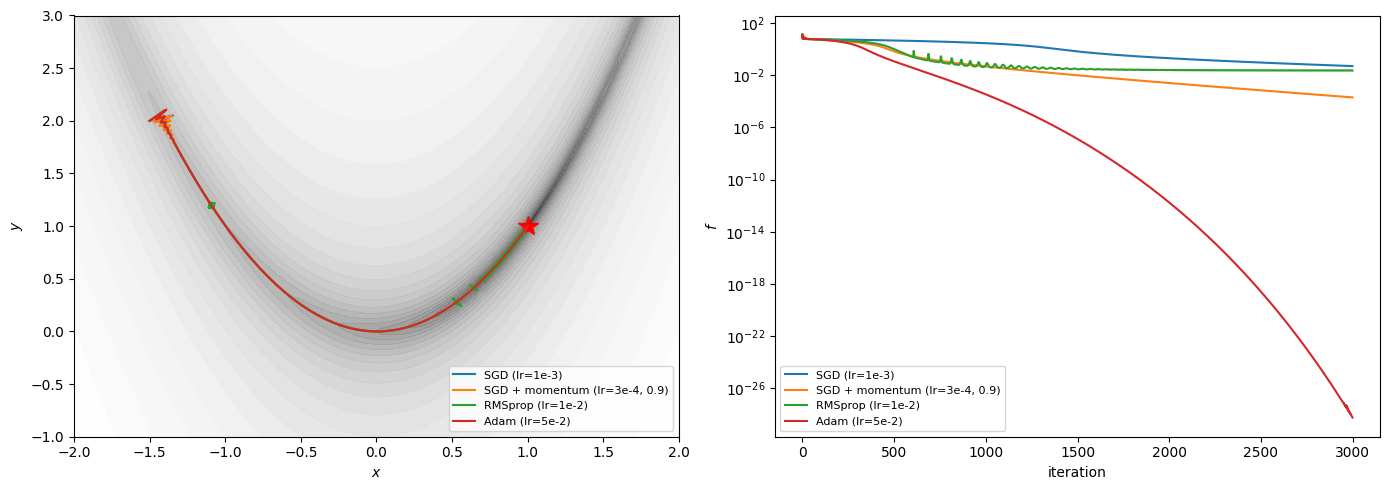

SGD (lr=1e-3)                    final f = 4.87e-02   final point = [0.7796 0.6068]
SGD + momentum (lr=3e-4, 0.9)    final f = 1.95e-04   final point = [0.9861 0.9723]
RMSprop (lr=1e-2)                final f = 2.24e-02   final point = [0.9678 0.9514]
Adam (lr=5e-2)                   final f = 5.82e-29   final point = [1. 1.]


In [24]:
def run(opt_class, n_steps=3000, start=(-1.5, 2.0), **opt_kwargs):
    p = torch.tensor(start, requires_grad=True)
    opt = opt_class([p], **opt_kwargs)
    path, losses = [p.detach().clone()], []
    for _ in range(n_steps):
        opt.zero_grad()
        loss = rosenbrock(p)
        loss.backward()
        opt.step()
        path.append(p.detach().clone()); losses.append(loss.item())
    return torch.stack(path), losses

setups = {
    "SGD (lr=1e-3)":               (torch.optim.SGD, dict(lr=1e-3)),
    "SGD + momentum (lr=3e-4, 0.9)": (torch.optim.SGD, dict(lr=3e-4, momentum=0.9)),
    "RMSprop (lr=1e-2)":           (torch.optim.RMSprop, dict(lr=1e-2)),
    "Adam (lr=5e-2)":              (torch.optim.Adam, dict(lr=5e-2)),
}
results = {name: run(cls, **kw) for name, (cls, kw) in setups.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
landscape(axes[0])
for i, (name, (path, losses)) in enumerate(results.items()):
    axes[0].plot(path[:, 0], path[:, 1], "-", color=f"C{i}", lw=1.5, label=name)
    axes[1].semilogy(losses, color=f"C{i}", label=name)
axes[0].legend(fontsize=8, loc="lower right"); axes[0].set_xlim(-2, 2); axes[0].set_ylim(-1, 3)
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("$f$"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
for name, (path, losses) in results.items():
    print(f"{name:32s} final f = {losses[-1]:.2e}   final point = {path[-1].numpy().round(4)}")

Reading the result: Adam reaches the minimum $(1, 1)$ to machine precision within 3000 steps, momentum comes close ($f \approx 2\times10^{-4}$), and plain SGD is still
moving slowly along the valley. RMSprop gets stuck at $f\approx2\times10^{-2}$, about 0.06 from the minimum. Since it divides the gradient by its own typical size,
its steps stay about as long as $\eta$ even near the minimum (0.014 on average over the last 500 steps), so it keeps jumping across the narrow valley
(the spikes in its loss curve). A smaller $\eta$ lowers this final error ($f\approx3\times10^{-3}$ with $\eta = 3\times10^{-3}$), but makes the start slower
($f\approx0.2$ after 3000 steps with $\eta = 10^{-3}$).

No optimiser is universally best, and each has hyperparameters (here: the learning rate) that strongly affect the result.
The same tools are used to fit neural networks, where the loss landscape has millions or more dimensions instead of two.

<hr/>
## 8. The inverse Schrödinger problem

### 8.1 Motivation
The usual (*direct*) problem of quantum mechanics is: given a potential $V(x)$, find the eigenstates and energies. Many questions in physics are **inverse**:
*which potential produces a prescribed state?*
- In experiments with ultracold atoms, the trapping potential is shaped with laser beams; one wants the potential that gives a desired density profile of the atomic cloud.
- In semiconductor quantum dots, gate voltages define the confining potential; one wants electrons localised in a prescribed way.
- In density-functional theory, the Kohn–Sham inversion problem asks for the potential whose ground-state density equals a given density.

Here we solve the simplest version: for one particle in 1D, find $V(x)$ such that the ground-state probability density $|\psi_0(x)|^2$ is as close as possible
to a target density $\rho_\ast(x)$.

### 8.2 Formulation as an optimisation problem
On the grid of Section 6 the potential is a vector of $N_x$ numbers $V_i = V(x_i)$; these are our **trainable parameters** (here $N_x = 300$).
For given $V$ we build $\bar H = \bar H_{\rm kin} + \mathrm{diag}(V)$, diagonalise it and take the ground state $\psi_0$. The loss compares amplitudes:
$$\mathcal L(V) = \sum_i \Big(|\psi_0(x_i)| - \sqrt{\rho_\ast(x_i)}\Big)^2\,\Delta x .$$
The factor $\Delta x$ makes the sum an approximation of the integral $\int\big(|\psi_0| - \sqrt{\rho_\ast}\big)^2dx$, so its value does not depend on the number of grid points.
We compare $|\psi_0|$ with $\sqrt{\rho_\ast}$ rather than $|\psi_0|^2$ with $\rho_\ast$: the square root gives more weight to regions where the density is small, which
otherwise hardly influence the loss. The gradient $\partial\mathcal L/\partial V_i$ for all 300 components comes from one backward pass through `eigh`.
We minimise with **L-BFGS**, a quasi-Newton method. Newton's method jumps to the minimum of the local quadratic approximation of the loss,
$\Delta\vec V = -(\nabla^2\mathcal L)^{-1}\nabla\mathcal L$, with the Hessian $\nabla^2\mathcal L$ (Section 7). Computing and inverting the $300\times300$ Hessian at every step is expensive;
a quasi-Newton method instead builds an approximation of $(\nabla^2\mathcal L)^{-1}$ from the gradients of previous steps.
This makes it fast for smooth problems with exact (non-stochastic) gradients. Within one step it evaluates the loss several times (a *line search*: several
step lengths are tried along the chosen direction), so `opt.step` receives a function, called `closure`, that recomputes the loss and its gradient.
(In Python, a function defined inside another function that uses that function's variables, here `opt`, `V` and `amp_target`, is called a closure.) One L-BFGS step contains up to `max_iter` such iterations (a setting explained in 8.3).

**Starting point.** We start from $V = 0$, not from a harmonic potential. The backward pass of `eigh` contains factors $1/(E_i - E_j)$ for all pairs of
eigenvalues, also those of highly excited states that do not enter the loss. In a symmetric potential with high walls at the edges of the grid, such as
$x^2/2$ on $[-6, 6]$, the highest states come in pairs localised at the left and right edge with numerically equal energies; the factor $1/0$ then turns
the gradient into `nan` (this is the warning of Section 6 in practice). The spectrum of the flat potential has no such degeneracies.

Two properties of the problem are worth knowing in advance:
- $V$ is determined only **up to a constant**: $V \to V + c$ shifts all energies by $c$ and leaves the states unchanged. We fix it by a shift: in 8.3 the potential is matched to the exact one in the high-density region, in 8.4 its minimum in that region is set to zero.
- Where the target density is practically zero, the potential has almost no influence on the loss, so it is **not determined** there.

### 8.3 A test with a known answer
For a node-less ground state the Schrödinger equation can be inverted exactly. Dividing $-\frac12\psi_0'' + V\psi_0 = E_0\psi_0$ by $\psi_0$, which is allowed
because $\psi_0 \neq 0$ everywhere (no nodes), gives $V(x) = E_0 + \frac{1}{2}\frac{\psi_0''(x)}{\psi_0(x)}$.
For the Gaussian $\psi_\ast(x)\propto e^{-x^2/(2\sigma^2)}$ we have $\psi_\ast''/\psi_\ast = x^2/\sigma^4 - 1/\sigma^2$, so $V(x) = \frac{x^2}{2\sigma^4} + \text{const}$, a harmonic potential.
We use this case to test the method. The target density is $\rho_\ast = |\psi_\ast|^2 \propto e^{-x^2/\sigma^2}$.

Details of the code:
- `torch.zeros_like(x)` creates a tensor of zeros with the shape and type of `x`. The trailing underscore in `requires_grad_(True)` marks a PyTorch method that
  modifies the tensor in place, here switching on gradient tracking.
- An eigensolver may return $\psi$ or $-\psi$ (both are eigenvectors), and the sign can change from one iteration to the next. The ground state has no nodes,
  so `torch.abs(psi[:, 0])` removes this ambiguity. Dividing by $\sqrt{\Delta x}$ converts the vector normalisation $\sum_i|\psi_i|^2 = 1$ of `eigh` into
  $\sum_i|\psi_i|^2\Delta x = 1$, as in Section 6.
- $\sigma = 0.7$ is arbitrary. Any width works that is much larger than $\Delta x \approx 0.04$ (so that the grid resolves the density) and much smaller than the
  half-width 6 of the box (so that the density vanishes at the walls).
- Settings of `torch.optim.LBFGS`:
  - `lr=1` means a full quasi-Newton step; the `line_search_fn="strong_wolfe"` then shortens or lengthens each step so that the loss really decreases
    by a sufficient amount. Without the line search a fixed step is taken; without it the run still converged, but to a noticeably larger loss.
  - `history_size=50` is the number of past gradients used to estimate the curvature; values from 10 to 100 give a final loss of the same order.
  - `tolerance_grad` and `tolerance_change` are the thresholds below which L-BFGS stops. The defaults ($10^{-7}$ and $10^{-9}$) are of the size of the loss
    reached here, and with them the optimisation stops early (after roughly 150–200 evaluations) at a loss a few times larger. We set them so small that they never stop the run.
  - Each call `opt.step(closure)` makes up to `max_iter=50` iterations, and the line search adds further loss evaluations: the default `n_steps=5` outer steps
    make about 270 evaluations of the loss, each with one diagonalisation and one backward pass. `n_steps` is kept small so that the notebook runs quickly.
    For the Gaussian target this costs little accuracy: with `n_steps=20` (about 1200 evaluations, four times longer) the final loss decreased in our tests
    by less than a factor of two and the plots looked the same. Harder targets profit more from extra steps (Section 8.4).
  - `opt.step(closure)` returns the loss at the *beginning* of the step. To record the loss after the last step, `closure()` is called once more at the end.

In [25]:
def ground_state_amplitude(V):
    # |psi_0| on the grid, normalised so that sum |psi_0|^2 dx = 1
    E, psi = torch.linalg.eigh(H_kin + torch.diag(V))
    return torch.abs(psi[:, 0]) / torch.sqrt(dx)

def invert(rho_target, n_steps=5):
    # Find V on the grid whose ground-state density is closest to rho_target (a tensor on the grid x)
    rho_target = rho_target / (rho_target.sum() * dx)            # normalise the target
    amp_target = torch.sqrt(rho_target)
    V = torch.zeros_like(x).requires_grad_(True)                 # start from a flat potential (see 'Starting point' in 8.2)
    opt = torch.optim.LBFGS([V], lr=1, max_iter=50, history_size=50, line_search_fn="strong_wolfe",
                            tolerance_grad=1e-12, tolerance_change=1e-16)
    history = []

    def closure():
        opt.zero_grad()
        amp = ground_state_amplitude(V)
        loss = torch.sum((amp - amp_target)**2) * dx
        loss.backward()                                          # gradient w.r.t. all components of V
        return loss

    for _ in range(n_steps):
        history.append(opt.step(closure).item())                 # step() returns the loss at the START of the step
    history.append(closure().item())                             # loss after the last step
    amp = ground_state_amplitude(V.detach())
    return V.detach(), amp**2, rho_target, history

sigma = 0.7
t0 = time.perf_counter()
V_opt, rho_opt, rho_star, hist = invert(torch.exp(-x**2 / sigma**2))
print(f"optimisation took {time.perf_counter() - t0:.1f} s, final loss {hist[-1]:.2e}")
print(f"max |rho_0 - rho_target| = {torch.max(torch.abs(rho_opt - rho_star)).item():.1e}")

optimisation took 1.8 s, final loss 1.26e-07
max |rho_0 - rho_target| = 1.9e-04


Loss history, target and achieved densities, and the optimised potential compared with the exact harmonic potential (shifted by a constant).
To fix the constant, we take the region where the target density exceeds $10^{-3}$ of its maximum, where the loss carries information about $V$, and shift
$V$ so that its mean difference from the exact potential in that region is zero. The threshold is arbitrary: with $10^{-2}$ or $10^{-4}$ the shift changes by about 0.02
and the picture is the same. Matching the potentials at $x = 0$ would be an equally valid choice.

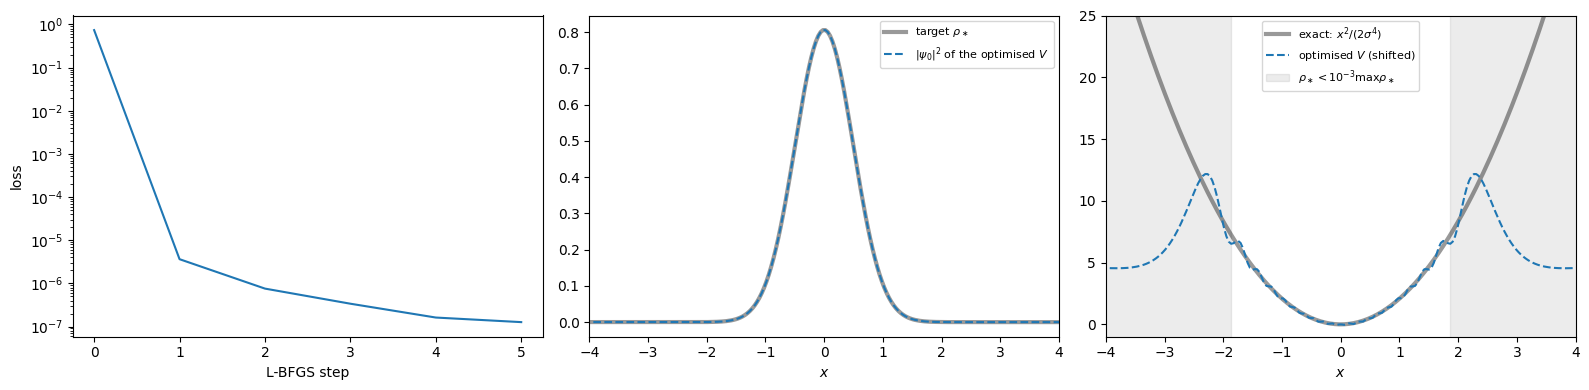

max |V_opt - V_exact| for |x| < 1.0: 0.120   (V_exact reaches 2.0 there)
max |V_opt - V_exact| for |x| < 1.5: 0.251   (V_exact reaches 4.5 there)
max |V_opt - V_exact| for |x| < 2.0: 0.878   (V_exact reaches 8.2 there)


In [26]:
V_exact = x**2 / (2 * sigma**4)
inside = rho_star > 1e-3 * rho_star.max()                    # region where the density is not negligible
shift = torch.mean((V_opt - V_exact)[inside])                # remove the arbitrary constant

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].semilogy(hist); axes[0].set_xlabel("L-BFGS step"); axes[0].set_ylabel("loss")
axes[1].plot(x, rho_star, "k", lw=3, alpha=0.4, label=r"target $\rho_\ast$")
axes[1].plot(x, rho_opt, "--", label=r"$|\psi_0|^2$ of the optimised $V$")
axes[1].set_xlim(-4, 4); axes[1].set_xlabel("$x$"); axes[1].legend(fontsize=8)
axes[2].plot(x, V_exact, "k", lw=3, alpha=0.4, label=r"exact: $x^2/(2\sigma^4)$")
axes[2].plot(x, V_opt - shift, "--", label="optimised $V$ (shifted)")
axes[2].fill_between(x, -2, 30, where=~inside, color="gray", alpha=0.15, label=r"$\rho_\ast < 10^{-3}\max\rho_\ast$")
axes[2].set_xlim(-4, 4); axes[2].set_ylim(-1, 25); axes[2].set_xlabel("$x$"); axes[2].legend(fontsize=8)
fig.tight_layout(); plt.show()
for R in [1.0, 1.5, 2.0]:
    m = x.abs() < R
    print(f"max |V_opt - V_exact| for |x| < {R}: {torch.max(torch.abs(V_opt - shift - V_exact)[m]).item():.3f}"
          f"   (V_exact reaches {V_exact[m].max().item():.1f} there)")

The density is reproduced closely, and in the central region the optimised potential agrees with the exact harmonic one. The deviation grows towards the edges,
where the density is small and the loss is almost insensitive to $V$; in the grey region the potential is not determined at all.
This is a general feature of inverse problems: the data constrain the answer only partly, and the result is meaningful only where the data carry information.

### 8.4 Non-trivial target densities
On the grid, a strictly positive density is the ground state of some potential, $V_i = E - (\bar H_{\rm kin}\psi)_i/\psi_i$ (row $i$ of the eigenvalue equation $(\bar H_{\rm kin}\vec\psi)_i + V_i\psi_i = E\psi_i$ solved for $V_i$), but this potential can be very large and irregular.
A density with exact zeros, such as the triangle below, cannot be reached at all. In both cases the minimisation returns the potential whose
ground-state density is *closest* to the target in the sense of the loss. Three examples:
- a **triangular** density, $\rho_\ast \propto \max(0, 1 - |x|/1.5)$, with kinks and exact zeros;
- a **flat-top** density, nearly constant on $[-1.5, 1.5]$ and falling off steeply;
- an **asymmetric** density with three peaks of heights 1, 0.6 and 0.4 (before normalisation).

The widths, positions and heights in these formulas are arbitrary choices that give three distinct shapes. `torch.clamp(t, min=0.0)` replaces all negative entries of `t` by 0.
The flat top $1/\big(1 + e^{(|x| - 1.5)/0.1}\big)$ is a smoothed step (the Fermi function): close to 1 for $|x| < 1.5$ and close to 0 outside, with edges of width about 0.1.
In the loop, `for col, (name, target) in enumerate(targets.items())` unpacks in one line the column number and the (name, density) pair.

All three use the default `n_steps=5` (about 280 loss evaluations each); the cell prints its own run time. The value is kept small so that the cell runs in a few seconds.
With `n_steps=20` the densities improve somewhat further (for the triangle the largest density error drops from about $8\times10^{-3}$ to $5\times10^{-3}$), at about four times the run time.
The three peaks are deliberately not too narrow: with narrower, more separated peaks the low density between them requires very high barriers, and the optimisation
needs many more steps.

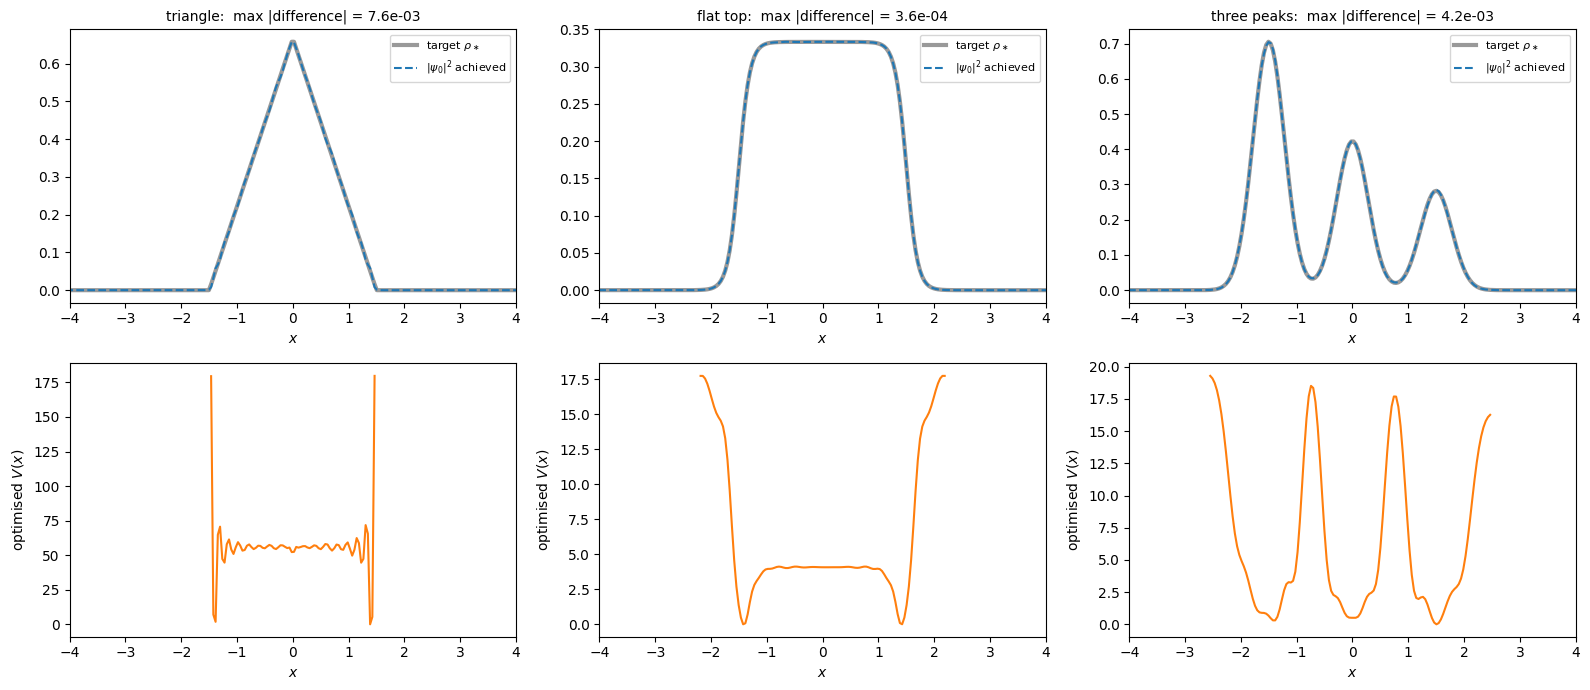

three inversions took 6 s


In [27]:
targets = {
    "triangle":    torch.clamp(1 - x.abs() / 1.5, min=0.0),
    "flat top":    1 / (1 + torch.exp((x.abs() - 1.5) / 0.1)),
    "three peaks": torch.exp(-(x + 1.5)**2 / 0.4**2) + 0.6 * torch.exp(-x**2 / 0.4**2)
                   + 0.4 * torch.exp(-(x - 1.5)**2 / 0.4**2),
}
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
t0 = time.perf_counter()
for col, (name, target) in enumerate(targets.items()):
    V_opt, rho_opt, rho_star, hist = invert(target)
    inside = rho_star > 1e-3 * rho_star.max()
    V_plot = V_opt - V_opt[inside].min()                       # fix the constant: minimum of V in the relevant region = 0
    axes[0, col].plot(x, rho_star, "k", lw=3, alpha=0.4, label=r"target $\rho_\ast$")
    axes[0, col].plot(x, rho_opt, "--", label=r"$|\psi_0|^2$ achieved")
    axes[0, col].set_title(f"{name}:  max |difference| = {torch.max(torch.abs(rho_opt - rho_star)).item():.1e}", fontsize=10)
    axes[1, col].plot(x[inside], V_plot[inside], color="C1")
    axes[1, col].set_ylabel("optimised $V(x)$")
    for ax in axes[:, col]:
        ax.set_xlim(-4, 4); ax.set_xlabel("$x$")
    axes[0, col].legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"three inversions took {time.perf_counter() - t0:.0f} s")

The potentials are shown only where the target density is non-negligible. The three-peak density requires three wells separated by barriers; the relative heights of the
peaks are set by the depths and the widths of the wells together, so the deepest well need not be under the highest peak (check this in your own run).
The flat-top density requires a potential that is flat in the middle, has narrow dips immediately inside the edges of the plateau (they make the density rise steeply there),
and rises steeply outside.
The triangular density is reproduced to the accuracy printed in the panel title, although it has exact zeros: the potential outside $|x| = 1.5$ is much higher than inside
(not shown; on average about three times the value inside in our run), which pushes the density there almost (but on the grid never exactly) to zero. Inside, the optimised potential oscillates from one grid point to the next.
Such grid-scale structure is a sign that the target cannot be produced by any smooth potential: the optimisation uses every degree of freedom of $V$ on the grid
to approach it.
Details of such optimised potentials, especially in regions of small density, can differ between computers (different linear-algebra libraries); the densities they produce do not.

This is the same scheme as training a neural network: a parametrised model (here: $V \mapsto \psi_0$ through the Schrödinger equation), a loss comparing the output with a target, and
gradients by automatic differentiation. Only the "model" is a physics computation instead of a network.
<hr/>
## 9. Summary
- Finite differences: $\mathcal O(m)$ cost, limited accuracy. Symbolic: exact but expression swell, no programs.
- AD: exact derivatives of *programs* via the chain rule on the computational graph.
  - forward mode (dual numbers): cost ∝ number of **inputs**;
  - reverse mode (backpropagation): cost ∝ number of **outputs** → ideal for a scalar loss of many parameters.
- PyTorch: `requires_grad=True`, `loss.backward()`, `.grad`; `torch.autograd.grad(..., create_graph=True)` for higher derivatives.
- Pitfalls: gradients accumulate → `zero_grad()`; the graph is freed after `backward()`; updates inside `torch.no_grad()`; `.detach()` before `.numpy()`.
- AD through `eigh` gives $dE_n/d\kappa$; agrees with Hellmann–Feynman.
- Training loop: `zero_grad → loss → backward → step`.
- Inverse Schrödinger problem: 300 grid values of $V$ optimised through `eigh` so that $|\psi_0|^2$ matches a target density.
<hr/>
## 10. Exercises

### Exercise 1 — By hand, then by machine
For $f(x_1, x_2) = x_1 x_2 + \sin x_1$ at $(x_1,x_2) = (\pi/2, 3)$:
1. Draw the computational graph and fill the forward (primal) table.
2. Compute $\partial f/\partial x_1$ and $\partial f/\partial x_2$ with the reverse-mode adjoint table (on paper).
3. Check with (a) the `Dual` class (two passes), (b) the `Var` class (add the missing `v_sin`), (c) `torch.autograd`.

#### Solution

In [28]:
# On paper, at (x1, x2) = (pi/2, 3):
#   forward:  v_-1 = x1 = pi/2,  v_0 = x2 = 3,  v_1 = v_-1 * v_0 = 3pi/2,  v_2 = sin(v_-1) = 1,  v_3 = v_1 + v_2 = y
#   backward: vbar_3 = 1,  vbar_1 = vbar_3 = 1,  vbar_2 = vbar_3 = 1,
#             vbar_0  = vbar_1 * v_-1                       = pi/2
#             vbar_-1 = vbar_1 * v_0 + vbar_2 * cos(v_-1)   = 3 + 0 = 3

# (a) forward mode with dual numbers: one pass per input, the seed (derivative part = 1) selects the input
a, b = math.pi / 2, 3.0
dy_dx1 = (Dual(a, 1) * Dual(b, 0) + d_sin(Dual(a, 1))).b     # seed x1
dy_dx2 = (Dual(a, 0) * Dual(b, 1) + d_sin(Dual(a, 0))).b     # seed x2
print("Dual :", dy_dx1, dy_dx2)

# (b) reverse mode with our Var class: we need the missing sin node.
#     Its local derivative d sin(v)/dv = cos(v) is stored for the backward pass.
def v_sin(v):
    return Var(math.sin(v.value), (v,), (math.cos(v.value),))

x1, x2 = Var(a), Var(b)
y = x1 * x2 + v_sin(x1)
y.backward()                      # one backward pass gives both derivatives
print("Var  :", x1.grad, x2.grad)

# (c) PyTorch
t1 = torch.tensor(a, requires_grad=True)
t2 = torch.tensor(b, requires_grad=True)
(t1 * t2 + torch.sin(t1)).backward()
print("torch:", t1.grad.item(), t2.grad.item())
print("exact: dy/dx1 = x2 + cos(x1) = 3,  dy/dx2 = x1 = pi/2 =", math.pi / 2)

Dual : 3.0 1.5707963267948966
Var  : 3.0 1.5707963267948966
torch: 3.0 1.5707963267948966
exact: dy/dx1 = x2 + cos(x1) = 3,  dy/dx2 = x1 = pi/2 = 1.5707963267948966


### Exercise 2 — Dual numbers for a neuron
1. Add `__truediv__` (quotient rule) and functions `d_exp`, `d_tanh` to the dual-number toolbox.
2. Using duals, compute the derivative of a single neuron's output $y = w_2\tanh(w_1 x + b)$ with respect to $w_1$ at $x=0.5$, $w_1=2$, $b=-1$, $w_2=1.5$.
3. Compare with `torch.autograd` and with the analytic result $w_2\,x\,(1-\tanh^2(w_1x+b))$.

#### Solution

In [29]:
# 1) Quotient rule for dual numbers: (a1 + b1 eps) / (a2 + b2 eps) = a1/a2 + (b1 a2 - a1 b2)/a2^2 eps
def _truediv(self, other):
    other = Dual.lift(other)
    return Dual(self.a / other.a, (self.b * other.a - self.a * other.b) / other.a**2)
Dual.__truediv__ = _truediv          # attach the method to the existing class

#    Elementary functions: g(a + b eps) = g(a) + g'(a) b eps
def d_exp(z):
    return Dual(math.exp(z.a), math.exp(z.a) * z.b)

def d_tanh(z):
    return Dual(math.tanh(z.a), (1 - math.tanh(z.a)**2) * z.b)     # tanh' = 1 - tanh^2

print("check exp: d/dz e^z at z=1 :", d_exp(Dual(1.0, 1.0)).b, "=", math.e)
print("check div: d/dz 1/z at z=2 :", (Dual(1.0) / Dual(2.0, 1.0)).b, "= -1/4")

# 2) Derivative of y = w2 tanh(w1 x + b) with respect to w1.
#    We want d/dw1, so w1 is the dual number with derivative part 1; x, b, w2 are plain constants.
x_in, w1, b, w2 = 0.5, 2.0, -1.0, 1.5
y = w2 * d_tanh(Dual(w1, 1.0) * x_in + b)
print("dual    :", y.b)

# 3) Comparison
tw1 = torch.tensor(w1, requires_grad=True)
(w2 * torch.tanh(tw1 * x_in + b)).backward()
print("torch   :", tw1.grad.item())
print("analytic:", w2 * x_in * (1 - math.tanh(w1 * x_in + b)**2))

check exp: d/dz e^z at z=1 : 2.718281828459045 = 2.718281828459045
check div: d/dz 1/z at z=2 : -0.25 = -1/4
dual    : 0.75
torch   : 0.75
analytic: 0.75


### Exercise 3 — Autodiff meets perturbation theory
Consider the anharmonic oscillator $\hat H(\lambda) = -\tfrac12\frac{d^2}{dx^2} + \tfrac12x^2 + \lambda x^4$.
First-order perturbation theory gives $E_n(\lambda) \approx (n+\tfrac12) + \lambda\,\langle n|x^4|n\rangle$ with
$\langle n|x^4|n\rangle = \tfrac34\,(2n^2 + 2n + 1)$ for the harmonic-oscillator eigenstates $|n\rangle$.
1. Using the grid Hamiltonian of Section 6 (`H_kin` and the grid `x`), compute $dE_n/d\lambda$ at $\lambda = 0$ for $n = 0,\dots,3$ with autograd
   (`torch.autograd.functional.jacobian` on a function returning the four lowest eigenvalues).
2. Compare with $\tfrac34(2n^2+2n+1)$. By the Hellmann–Feynman theorem the two must agree; what limits the agreement here?
3. Plot $E_n(\lambda)$ for $\lambda\in[0, 0.2]$ together with the first-order lines $(n+\tfrac12) + \lambda\,\tfrac34(2n^2+2n+1)$. For which $n$ does first-order perturbation theory fail first? Give the reason.

#### Solution

n = 0:  autograd dE/dlambda =   0.7497   <n|x^4|n> =  0.750
n = 1:  autograd dE/dlambda =   3.7477   <n|x^4|n> =  3.750
n = 2:  autograd dE/dlambda =   9.7412   <n|x^4|n> =  9.750
n = 3:  autograd dE/dlambda =  18.7271   <n|x^4|n> = 18.750


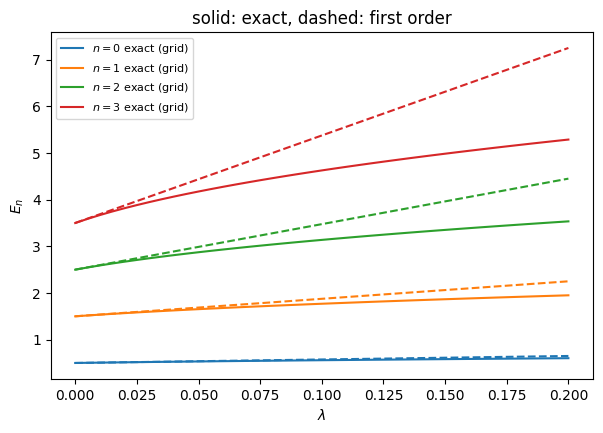

In [30]:
def levels(lam, n_levels=4):
    # Four lowest eigenvalues of H(lambda) = H_kin + x^2/2 + lambda x^4 on the grid
    return torch.linalg.eigvalsh(H_kin + torch.diag(0.5 * x**2 + lam * x**4))[:n_levels]

# 1) derivatives at lambda = 0: the jacobian of a function R -> R^4 is a vector of 4 numbers
dE = torch.autograd.functional.jacobian(levels, torch.tensor(0.0))

# 2) comparison with first-order perturbation theory
for n in range(4):
    pt = 0.75 * (2 * n**2 + 2 * n + 1)
    print(f"n = {n}:  autograd dE/dlambda = {dE[n].item():8.4f}   <n|x^4|n> = {pt:6.3f}")
# By Hellmann-Feynman, dE_n/dlambda at lambda = 0 equals <n|x^4|n> exactly. The small difference
# (about 0.1 % for n = 3) is the error of the finite-difference grid (dx = 0.04): the grid
# eigenstates are not exactly the harmonic-oscillator states. A finer grid reduces it.

# 3) E_n(lambda) vs the first-order approximation
lams = torch.linspace(0, 0.2, 41)
E_grid = torch.stack([levels(l) for l in lams])           # shape (41, 4)
fig, ax = plt.subplots(figsize=(7, 4.5))
for n in range(4):
    ax.plot(lams, E_grid[:, n], color=f"C{n}", label=f"$n={n}$ exact (grid)")
    ax.plot(lams, (n + 0.5) + lams * 0.75 * (2 * n**2 + 2 * n + 1), "--", color=f"C{n}")
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel("$E_n$"); ax.set_title("solid: exact, dashed: first order")
ax.legend(fontsize=8); plt.show()
# The first-order correction grows like n^2, while the level spacing is 1. Perturbation theory is
# reliable only while lambda <n|x^4|n> << 1, so it fails first for the highest level shown (n = 3).

### Exercise 4 — Inverse problem: design the barrier
We want a double well whose tunnelling gap is exactly $\Delta E^{\ast} = E_1 - E_0 = 0.05$.
Find $\kappa$ by gradient-based optimisation: minimise $\mathcal L(\kappa) = \big(\log\Delta E(\kappa) - \log\Delta E^{\ast}\big)^2$ with `torch.optim.Adam` (start at $\kappa=1$, `lr=0.1`, 300 steps).
With Adam the parameter changes by at most about `lr` per step, so going from $\kappa = 1$ to a value near 5 takes at least about 40 steps; the 300 steps leave room for the final convergence.
Plot $\mathcal L$ and $\kappa$ versus iteration and check the result on the $E_n(\kappa)$ plot of Section 6. Why is it a good idea to compare logarithms?

#### Solution

kappa* = 4.7285,  gap = 0.05000  (target 0.05)


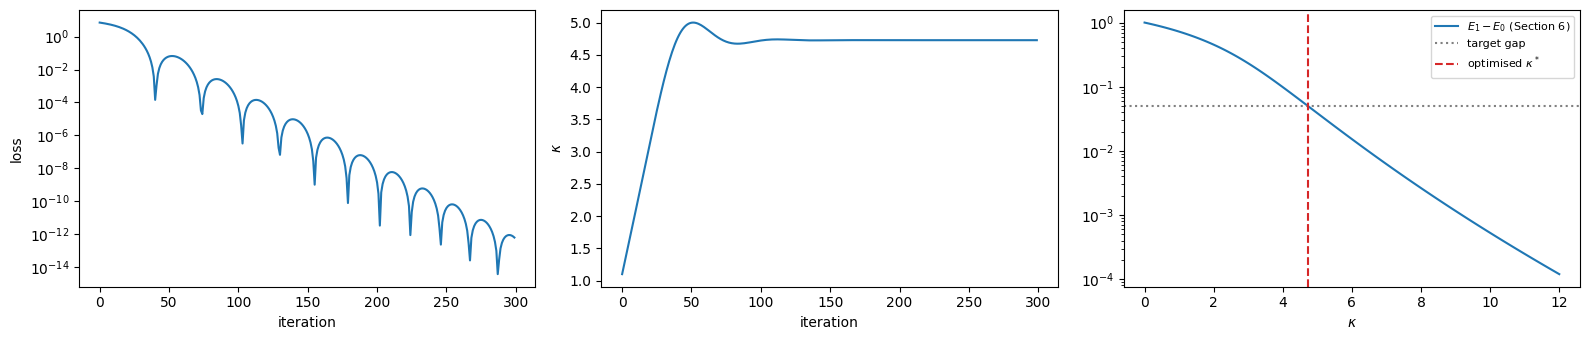

In [31]:
target_gap = 0.05
kappa = torch.tensor(1.0, requires_grad=True)       # starting value of the parameter we optimise
opt = torch.optim.Adam([kappa], lr=0.1)

hist_loss, hist_kappa = [], []
for step in range(300):
    opt.zero_grad()                                  # reset the gradient from the previous step
    E = energies(kappa, 2)                           # the two lowest levels (diagonalisation inside)
    gap = E[1] - E[0]
    # torch.log on gap, because the gradient must flow through it; the target is a fixed number, so math.log suffices
    loss = (torch.log(gap) - math.log(target_gap))**2
    loss.backward()                                  # d loss / d kappa, through eigvalsh
    opt.step()                                       # update kappa
    hist_loss.append(loss.item())
    hist_kappa.append(kappa.item())

E = energies(kappa.detach(), 2)
print(f"kappa* = {kappa.item():.4f},  gap = {(E[1] - E[0]).item():.5f}  (target {target_gap})")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
axes[0].semilogy(hist_loss); axes[0].set_ylabel("loss")
axes[1].plot(hist_kappa); axes[1].set_ylabel(r"$\kappa$")
# check with the data of Section 6: the gap E_1 - E_0 as a function of kappa, and the optimised kappa*
axes[2].semilogy(kappas, E_all[:, 1] - E_all[:, 0], label="$E_1 - E_0$ (Section 6)")
axes[2].axhline(target_gap, color="gray", ls=":", label="target gap")
axes[2].axvline(kappa.item(), color="C3", ls="--", label=r"optimised $\kappa^*$")
axes[2].set_xlabel(r"$\kappa$"); axes[2].legend(fontsize=8)
for ax in axes[:2]: ax.set_xlabel("iteration")
fig.tight_layout(); plt.show()
# The gap decreases roughly exponentially with kappa. In log(gap) the dependence is almost linear,
# so the loss is a simple parabola in kappa. With (gap - target)^2 the loss and its gradient would be
# extremely small for large kappa, and the optimiser would hardly move.

### Exercise 5 (advanced) — The variational principle with autograd
For the anharmonic oscillator $V(x) = \tfrac12 x^2 + \lambda x^4$ with $\lambda = 0.5$, take the trial wavefunction
$\psi_{\alpha,\beta}(x) \propto \exp(-\alpha x^2 - \beta x^4)$ on the grid of Section 6 (with $\alpha, \beta>0$; parametrise them as `exp` of trainable numbers to keep them positive).
The Rayleigh quotient $E = \vec\psi^{T}\bar H\vec\psi/\vec\psi^{T}\vec\psi$ is, by the variational principle, never below the lowest eigenvalue of $\bar H$, whatever $\vec\psi$ is. Minimising it over $\alpha, \beta$
therefore gives the best upper bound on the ground-state energy within this family of wavefunctions.
1. Write $E(\alpha,\beta) = \dfrac{\vec\psi^{T}\bar H\vec\psi}{\vec\psi^{T}\vec\psi}$ using the grid Hamiltonian.
2. Minimise it with Adam (for example `lr=0.03`, 1500 steps, starting from $\alpha = 1$, $\beta = e^{-3}\approx0.05$). Compare with the exact ground-state energy from `eigvalsh`, and with the best pure Gaussian ($\beta = 0$).
3. Plot the exact ground state and both variational wavefunctions.

#### Solution

exact      E0 = 0.696046
Gaussian   E  = 0.701521
Gauss+x^4  E  = 0.696061


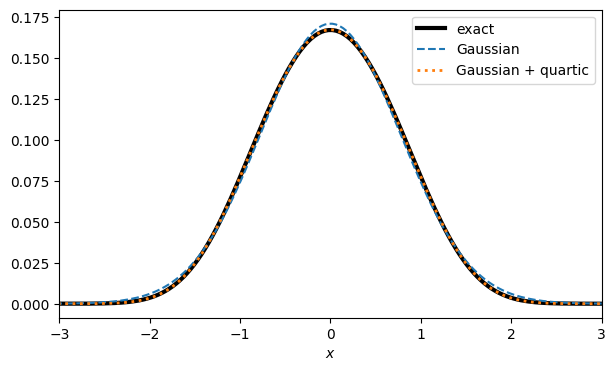

In [32]:
lam = 0.5
H_anh = H_kin + torch.diag(0.5 * x**2 + lam * x**4)     # grid Hamiltonian of the anharmonic oscillator
evals, evecs = torch.linalg.eigh(H_anh)                 # reference: exact diagonalisation

def variational(use_beta, steps=1500):
    """Minimise E(alpha, beta) = <psi|H|psi>/<psi|psi> for psi = exp(-alpha x^2 - beta x^4)."""
    # alpha = exp(log_a) and beta = exp(log_b) are always positive, whatever value log_a, log_b take.
    # Start: alpha = 1 (the harmonic value is 1/2) and a small quartic correction beta = e^-3 ~ 0.05. Other starts of this
    # order give the same result. With lr = 0.03 the energy stops changing after about 500 steps; 1500 steps is a safe margin.
    log_a = torch.tensor(0.0, requires_grad=True)
    log_b = torch.tensor(-3.0, requires_grad=use_beta)
    params = [log_a] + ([log_b] if use_beta else [])
    opt = torch.optim.Adam(params, lr=0.03)
    for _ in range(steps):
        opt.zero_grad()
        beta = torch.exp(log_b) if use_beta else 0.0
        psi = torch.exp(-torch.exp(log_a) * x**2 - beta * x**4)    # trial wavefunction on the grid
        # @ is matrix multiplication; for a vector psi and a matrix H, psi @ H @ psi is the number psi^T H psi.
        # The quotient (Rayleigh quotient) is never below the lowest eigenvalue: the variational principle.
        E = psi @ H_anh @ psi / (psi @ psi)
        E.backward()
        opt.step()
    return E.item(), (psi / psi.norm()).detach()

E_g, psi_g = variational(use_beta=False)        # pure Gaussian
E_gb, psi_gb = variational(use_beta=True)       # Gaussian times exp(-beta x^4)
print(f"exact      E0 = {evals[0].item():.6f}")
print(f"Gaussian   E  = {E_g:.6f}")
print(f"Gauss+x^4  E  = {E_gb:.6f}")
# Variational principle: both values lie above the exact E0; the richer ansatz is closer.

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, evecs[:, 0].abs(), "k", lw=3, label="exact")   # abs(): eigh may return -psi
ax.plot(x, psi_g, "--", label="Gaussian")
ax.plot(x, psi_gb, ":", lw=2, label="Gaussian + quartic")
ax.set_xlim(-3, 3); ax.legend(); ax.set_xlabel("$x$"); plt.show()

### Exercise 6 (advanced, optional) — Quantum phase transition in the transverse-field Ising chain
This exercise uses a many-body quantum system, which we will study properly later in the course. For $L$ spins-1/2 with periodic boundaries,
$$\hat H(h) = -\sum_{i=1}^{L}\hat\sigma^z_i\hat\sigma^z_{i+1} - h\sum_{i=1}^{L}\hat\sigma^x_i .$$
In the thermodynamic limit there is a quantum phase transition at $h_c=1$ (ferromagnet $\to$ paramagnet).
1. Build $\hat H(h)$ as a $2^L\times2^L$ matrix for $L=6$ using `torch.kron`: write a helper `site_op(op, i, L)` that returns the operator `op` acting on site `i` of an `L`-site chain (identity elsewhere).
   `torch.kron(A, B)` is the Kronecker product $A\otimes B$, the block matrix whose block $(i, j)$ is $A_{ij}B$. An operator acting on site $i$ of the chain is
   $\mathbb 1\otimes\dots\otimes\hat\sigma\otimes\dots\otimes\mathbb 1$, with $\hat\sigma$ at position $i$.
2. With autograd compute $e_0'(h) = \frac{d}{dh}\frac{E_0}{L}$ for $h\in[0.2, 2]$. Verify it against Hellmann–Feynman: $e_0'(h) = -\frac{1}{L}\langle\psi_0|\sum_i\hat\sigma^x_i|\psi_0\rangle$ (minus the transverse magnetisation per site, $-m_x$).
3. Compute $e_0''(h)$ by central finite differences of the autograd derivative and plot it. Where is its extremum? Repeat for $L=8$. What happens as $L$ grows?
   ($L = 10$ also works but is much slower: the matrix is $1024\times1024$ and one diagonalisation takes about 30 times longer than for $L = 8$.)
4. Try computing $e_0''(h)$ by differentiating twice with autograd (`create_graph=True`). The result is `nan`; explain the reason using the remark about degeneracies in Section 6.

#### Solution

L=6: max |autograd - Hellmann-Feynman| = 3.33e-16
       minimum of e0''(h) at h = 0.830


L=8: max |autograd - Hellmann-Feynman| = 1.11e-16
       minimum of e0''(h) at h = 0.890


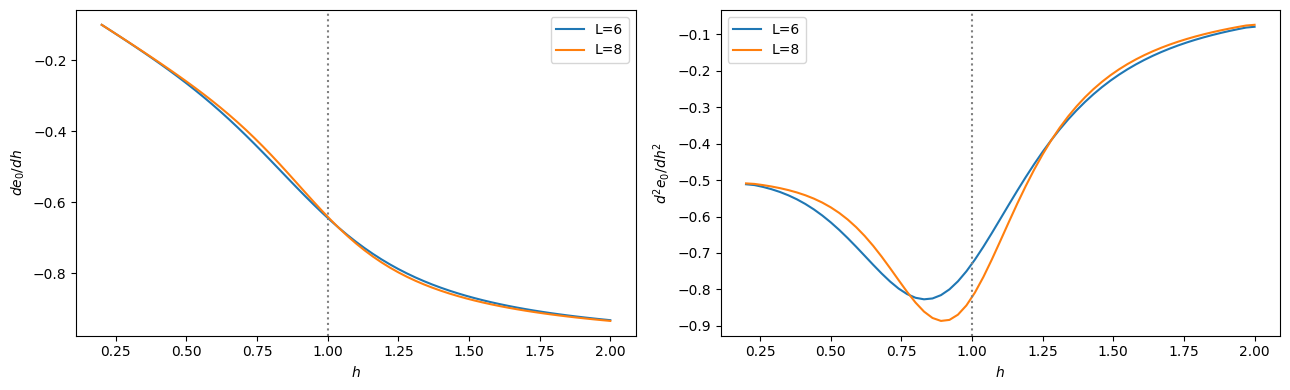

second derivative with autograd twice: nan


In [33]:
# Pauli matrices and the 2x2 identity
sx = torch.tensor([[0., 1.], [1., 0.]])
sz = torch.tensor([[1., 0.], [0., -1.]])
id2 = torch.eye(2)

def site_op(op, i, L):
    """op acting on site i of an L-site chain: id x ... x op x ... x id (Kronecker products)."""
    out = torch.ones(1, 1)
    for j in range(L):
        out = torch.kron(out, op if j == i else id2)
    return out

hs = torch.linspace(0.2, 2.0, 61)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for L in [6, 8]:                                     # L = 10 works too, but takes about 10 s
    # 1) Hamiltonian pieces. (i + 1) % L connects the last site to the first (periodic boundaries).
    ZZ = sum(site_op(sz, i, L) @ site_op(sz, (i + 1) % L, L) for i in range(L))
    X = sum(site_op(sx, i, L) for i in range(L))

    # 2) e0'(h) by autograd, and the Hellmann-Feynman value for comparison
    d1, hf = [], []
    for hv in hs:
        h = hv.clone().requires_grad_(True)          # a fresh leaf tensor for each h
        E, V = torch.linalg.eigh(-ZZ - h * X)
        (E[0] / L).backward()                        # d(E0/L)/dh  ->  h.grad
        d1.append(h.grad.item())
        psi0 = V[:, 0].detach()                      # ground state (detached: no gradient needed here)
        hf.append(-(psi0 @ X @ psi0).item() / L)     # <psi0| dH/dh |psi0> / L  with dH/dh = -X
    d1, hf = np.array(d1), np.array(hf)
    print(f"L={L}: max |autograd - Hellmann-Feynman| = {np.abs(d1 - hf).max():.2e}")

    # 3) second derivative by central finite differences of the autograd first derivative
    d2 = np.gradient(d1, hs.numpy())
    print(f"       minimum of e0''(h) at h = {hs[np.argmin(d2)].item():.3f}")
    axes[0].plot(hs, d1, label=f"L={L}")
    axes[1].plot(hs, d2, label=f"L={L}")

axes[0].set_ylabel("$de_0/dh$"); axes[1].set_ylabel("$d^2e_0/dh^2$")
for ax in axes:
    ax.axvline(1, color="gray", ls=":")             # h_c = 1 of the infinite chain
    ax.set_xlabel("$h$"); ax.legend()
fig.tight_layout(); plt.show()
# The extremum of e0'' moves towards h_c = 1 as L grows: a finite-size precursor of the
# quantum phase transition (in the infinite chain e0'' diverges logarithmically at h_c).

# 4) Second derivative by applying autograd twice
h = torch.tensor(1.0, requires_grad=True)
e0 = torch.linalg.eigvalsh(-ZZ - h * X)[0] / L
(g1,) = torch.autograd.grad(e0, h, create_graph=True)   # keep the graph of the first derivative
(g2,) = torch.autograd.grad(g1, h)
print("second derivative with autograd twice:", g2.item())
# Mathematically e0'' is finite: by second-order perturbation theory it involves only the gaps E_m - E_0 to the
# non-degenerate ground state. The nan is an artefact of the implementation: PyTorch's backward formula for eigh builds
# the full matrix of factors 1/(E_j - E_i) for ALL pairs of levels. The TFIM spectrum has exactly degenerate excited
# levels (momenta +k and -k), so this matrix contains inf, and inf * 0 = nan. The finite-difference route above avoids this.